# DATASET ACQUISITION AND LOADING

In [1]:
# ============================================================
# STEP 1: DATASET ACQUISITION AND LOADING
# Dataset: Personalized Tourism Route Planning Dataset
# ============================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Define Dataset Path
# ------------------------------------------------------------

dataset_path = r"F:\.0 Work\4541\Personalized_Tourism_Route_Planning_Dataset.csv"

# ------------------------------------------------------------
# 2. Check Dataset Availability
# ------------------------------------------------------------

if not os.path.exists(dataset_path):
    raise FileNotFoundError(
        f"Dataset not found at the specified path: {dataset_path}"
    )

print("=" * 70)
print("STEP 1: DATASET ACQUISITION")
print("=" * 70)

print("\nDataset file successfully located.")
print("Dataset Path:", dataset_path)

# ------------------------------------------------------------
# 3. Load CSV Dataset
# ------------------------------------------------------------

try:
    df = pd.read_csv(dataset_path, encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv(dataset_path, encoding="latin1")

# ------------------------------------------------------------
# 4. Display Dataset Dimensions
# ------------------------------------------------------------

print("\n========== DATASET DIMENSIONS ==========")

print("Number of Records:", df.shape[0])
print("Number of Columns:", df.shape[1])

# ------------------------------------------------------------
# 5. Display Column Names
# ------------------------------------------------------------

print("\n========== DATASET ATTRIBUTES ==========")

for index, column in enumerate(df.columns, start=1):
    print(f"{index}. {column}")

# ------------------------------------------------------------
# 6. Display First Five Records
# ------------------------------------------------------------

print("\n========== FIRST FIVE RECORDS ==========")
print(df.head())

# ------------------------------------------------------------
# 7. Display Data Types
# ------------------------------------------------------------

print("\n========== ATTRIBUTE DATA TYPES ==========")
print(df.dtypes)

# ------------------------------------------------------------
# 8. Display Dataset Information
# ------------------------------------------------------------

print("\n========== DATASET INFORMATION ==========")
df.info()

# ------------------------------------------------------------
# 9. Display Numerical Summary
# ------------------------------------------------------------

print("\n========== NUMERICAL ATTRIBUTE SUMMARY ==========")
print(df.describe().T)

# ------------------------------------------------------------
# 10. Display Categorical Summary
# ------------------------------------------------------------

print("\n========== CATEGORICAL ATTRIBUTE SUMMARY ==========")

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

if len(categorical_columns) > 0:
    print(df[categorical_columns].describe().T)
else:
    print("No categorical attributes identified.")

# ------------------------------------------------------------
# 11. Identify Target Attribute
# ------------------------------------------------------------

target_column = "target_route_plan_category"

print("\n========== TARGET ATTRIBUTE ==========")

if target_column in df.columns:
    print("Target Attribute:", target_column)
    print("\nTarget Class Distribution:")
    print(df[target_column].value_counts())

    print("\nTarget Class Distribution (%):")
    print(
        (df[target_column].value_counts(normalize=True) * 100)
        .round(2)
    )
else:
    print("Warning: Target column not found.")

# ------------------------------------------------------------
# 12. Dataset Acquisition Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET ACQUISITION COMPLETED")
print("=" * 70)

print("Dataset Name: Personalized Tourism Route Planning Dataset")
print("Total Records:", df.shape[0])
print("Total Attributes:", df.shape[1])
print("Numerical Attributes:",
      len(df.select_dtypes(include=np.number).columns))
print("Categorical Attributes:",
      len(df.select_dtypes(include=["object", "category"]).columns))

print("\nDataset is ready for Step 2: Data Validation and Quality Assessment.")

C:\Users\S3\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\S3\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


STEP 1: DATASET ACQUISITION

Dataset file successfully located.
Dataset Path: F:\.0 Work\4541\Personalized_Tourism_Route_Planning_Dataset.csv

========== DATASET DIMENSIONS ==========
Number of Records: 7000
Number of Columns: 68

========== DATASET ATTRIBUTES ==========
1. sample_id
2. traveler_id
3. session_id
4. age_group
5. traveler_type
6. travel_companion_count
7. trip_purpose
8. preferred_activity
9. budget_level
10. walking_preference
11. transport_preference
12. crowd_tolerance
13. weather_sensitivity
14. accessibility_need
15. language_preference
16. city_zone
17. destination_category
18. season
19. day_type
20. time_slot
21. current_latitude
22. current_longitude
23. destination_latitude
24. destination_longitude
25. distance_to_destination_km
26. route_distance_km
27. available_time_min
28. planned_stops_count
29. historic_visit_count
30. avg_past_user_rating
31. daily_budget_inr
32. average_spending_inr
33. mobile_battery_pct
34. device_signal_strength_dbm
35. user_locatio

C:\Users\S3\AppData\Local\Temp\ipykernel_15752\1720561434.py:93: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(
C:\Users\S3\AppData\Local\Temp\ipykernel_15752\1720561434.py:137: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#strin

# DATA VALIDATION AND QUALITY ASSESSMENT

In [2]:
# ============================================================
# STEP 2: DATA VALIDATION AND QUALITY ASSESSMENT
# Dataset: Personalized Tourism Route Planning Dataset
# ============================================================

import os
import pandas as pd
import numpy as np

# ============================================================
# 1. LOAD DATASET
# ============================================================

dataset_path = r"F:\.0 Work\4541\Personalized_Tourism_Route_Planning_Dataset.csv"

output_dir = r"F:\.0 Work\4541\Step_2_Results"
os.makedirs(output_dir, exist_ok=True)

df = pd.read_csv(dataset_path)

print("=" * 75)
print("STEP 2: DATA VALIDATION AND QUALITY ASSESSMENT")
print("=" * 75)

print("\nOriginal Dataset Shape:", df.shape)

# ============================================================
# 2. MISSING VALUE ANALYSIS
# ============================================================

print("\n========== 1. MISSING VALUE ANALYSIS ==========")

missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage.round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Count", ascending=False
)

print(missing_report)

total_missing = int(missing_count.sum())

print("\nTotal Missing Values:", total_missing)

missing_report.to_csv(
    os.path.join(output_dir, "Missing_Value_Report.csv")
)

# ============================================================
# 3. DUPLICATE RECORD ANALYSIS
# ============================================================

print("\n========== 2. DUPLICATE RECORD ANALYSIS ==========")

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

duplicate_report = df[df.duplicated(keep=False)]

if not duplicate_report.empty:
    duplicate_report.to_csv(
        os.path.join(output_dir, "Duplicate_Records.csv"),
        index=False
    )

print("Unique Records:", df.drop_duplicates().shape[0])

# ============================================================
# 4. DATA TYPE VALIDATION
# ============================================================

print("\n========== 3. DATA TYPE VALIDATION ==========")

dtype_report = pd.DataFrame({
    "Attribute": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Unique_Values": [
        df[col].nunique(dropna=False) for col in df.columns
    ]
})

print(dtype_report.to_string(index=False))

dtype_report.to_csv(
    os.path.join(output_dir, "Data_Type_Report.csv"),
    index=False
)

# ============================================================
# 5. CONSTANT AND LOW-VARIANCE ATTRIBUTE ANALYSIS
# ============================================================

print("\n========== 4. CONSTANT ATTRIBUTE ANALYSIS ==========")

unique_counts = df.nunique(dropna=False)

constant_columns = unique_counts[
    unique_counts <= 1
].index.tolist()

print("Constant Attributes:", constant_columns)
print("Number of Constant Attributes:", len(constant_columns))

# Low-variation numerical columns are flagged for inspection.
# They are not automatically removed.

numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

low_variation_columns = []

for col in numeric_columns:
    if df[col].nunique() <= 5:
        low_variation_columns.append(col)

print("\nNumerical Attributes with 5 or Fewer Unique Values:")
print(low_variation_columns)

# ============================================================
# 6. OUTLIER DETECTION USING IQR METHOD
# ============================================================

print("\n========== 5. OUTLIER DETECTION ==========")

outlier_results = []

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())

    outlier_percentage = (
        outlier_count / len(df)
    ) * 100

    outlier_results.append({
        "Attribute": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": round(outlier_percentage, 2)
    })

outlier_report = pd.DataFrame(outlier_results)

outlier_report = outlier_report.sort_values(
    by="Outlier_Count",
    ascending=False
)

print(outlier_report.to_string(index=False))

outlier_report.to_csv(
    os.path.join(output_dir, "Outlier_Analysis_Report.csv"),
    index=False
)

# ============================================================
# 7. IDENTIFIER UNIQUENESS AND REPEATED RECORD ANALYSIS
# ============================================================

print("\n========== 6. IDENTIFIER VALIDATION ==========")

identifier_columns = [
    "sample_id",
    "traveler_id",
    "session_id"
]

identifier_results = []

for col in identifier_columns:

    if col in df.columns:

        identifier_results.append({
            "Identifier": col,
            "Total_Records": len(df),
            "Unique_Values": df[col].nunique(),
            "Repeated_Values": int(
                df[col].duplicated(keep=False).sum()
            ),
            "Missing_Values": int(df[col].isnull().sum())
        })

identifier_report = pd.DataFrame(identifier_results)

print(identifier_report.to_string(index=False))

identifier_report.to_csv(
    os.path.join(output_dir, "Identifier_Validation_Report.csv"),
    index=False
)

# Repeated traveler analysis

if "traveler_id" in df.columns:

    traveler_frequency = df["traveler_id"].value_counts()

    repeated_travelers = traveler_frequency[
        traveler_frequency > 1
    ]

    print("\nTotal Unique Travelers:",
          df["traveler_id"].nunique())

    print("Travelers with Repeated Records:",
          len(repeated_travelers))

    print("Maximum Records per Traveler:",
          traveler_frequency.max())

    repeated_travelers.rename(
        "Record_Count"
    ).to_csv(
        os.path.join(output_dir, "Repeated_Traveler_Report.csv")
    )

# ============================================================
# 8. TARGET CLASS DISTRIBUTION
# ============================================================

print("\n========== 7. TARGET CLASS DISTRIBUTION ==========")

target_column = "target_route_plan_category"

if target_column in df.columns:

    target_counts = df[target_column].value_counts(
        dropna=False
    )

    target_percentage = (
        df[target_column].value_counts(normalize=True,
                                       dropna=False) * 100
    )

    target_report = pd.DataFrame({
        "Class_Count": target_counts,
        "Class_Percentage": target_percentage.round(2)
    })

    print(target_report)

    print("\nNumber of Target Classes:",
          df[target_column].nunique())

    print("Majority Class:",
          target_counts.idxmax())

    print("Minority Class:",
          target_counts.idxmin())

    imbalance_ratio = (
        target_counts.max() / target_counts.min()
    )

    print("Class Imbalance Ratio:",
          round(imbalance_ratio, 2))

    target_report.to_csv(
        os.path.join(output_dir, "Target_Class_Report.csv")
    )

else:
    print("Target column not found.")

# ============================================================
# 9. NUMERICAL RANGE VALIDATION
# ============================================================

print("\n========== 8. NUMERICAL RANGE VALIDATION ==========")

range_rules = {
    "current_latitude": (-90, 90),
    "destination_latitude": (-90, 90),
    "current_longitude": (-180, 180),
    "destination_longitude": (-180, 180),
    "mobile_battery_pct": (0, 100),
    "humidity_pct": (0, 100),
    "rainfall_probability_pct": (0, 100),
    "local_node_load_pct": (0, 100),
    "public_transport_availability": (0, 100),
    "parking_availability_score": (0, 100),
    "safety_index": (0, 100),
    "scenic_value_score": (0, 100),
    "route_comfort_score": (0, 100),
    "route_interest_match_score": (0, 100),
    "route_safety_score": (0, 100),
    "route_context_score": (0, 100),
    "review_score": (0, 5),
    "walking_speed_kmph": (0, 20),
    "distance_to_destination_km": (0, None),
    "route_distance_km": (0, None),
    "estimated_travel_time_min": (0, None),
    "estimated_cost_inr": (0, None)
}

range_results = []

for col, (lower, upper) in range_rules.items():

    if col not in df.columns:
        continue

    invalid_mask = pd.Series(False, index=df.index)

    if lower is not None:
        invalid_mask |= df[col] < lower

    if upper is not None:
        invalid_mask |= df[col] > upper

    range_results.append({
        "Attribute": col,
        "Minimum_Value": df[col].min(),
        "Maximum_Value": df[col].max(),
        "Expected_Minimum": lower,
        "Expected_Maximum": upper,
        "Invalid_Count": int(invalid_mask.sum())
    })

range_report = pd.DataFrame(range_results)

print(range_report.to_string(index=False))

range_report.to_csv(
    os.path.join(output_dir, "Numerical_Range_Report.csv"),
    index=False
)

# ============================================================
# 10. GEOGRAPHIC COORDINATE VALIDATION
# ============================================================

print("\n========== 9. GEOGRAPHIC VALIDATION ==========")

coordinate_columns = [
    "current_latitude",
    "current_longitude",
    "destination_latitude",
    "destination_longitude"
]

if all(col in df.columns for col in coordinate_columns):

    invalid_coordinates = (
        ~df["current_latitude"].between(-90, 90) |
        ~df["destination_latitude"].between(-90, 90) |
        ~df["current_longitude"].between(-180, 180) |
        ~df["destination_longitude"].between(-180, 180)
    )

    print("Invalid Coordinate Records:",
          int(invalid_coordinates.sum()))

    # Haversine distance calculation

    def haversine_distance(lat1, lon1, lat2, lon2):

        earth_radius_km = 6371.0

        lat1 = np.radians(lat1)
        lon1 = np.radians(lon1)
        lat2 = np.radians(lat2)
        lon2 = np.radians(lon2)

        dlat = lat2 - lat1
        dlon = lon2 - lon1

        a = (
            np.sin(dlat / 2) ** 2
            + np.cos(lat1) * np.cos(lat2)
            * np.sin(dlon / 2) ** 2
        )

        c = 2 * np.arctan2(
            np.sqrt(a),
            np.sqrt(1 - a)
        )

        return earth_radius_km * c

    df["haversine_distance_km"] = haversine_distance(
        df["current_latitude"],
        df["current_longitude"],
        df["destination_latitude"],
        df["destination_longitude"]
    )

    if "distance_to_destination_km" in df.columns:

        distance_correlation = df[
            ["haversine_distance_km",
             "distance_to_destination_km"]
        ].corr().iloc[0, 1]

        print("Haversine vs Reported Distance Correlation:",
              round(distance_correlation, 4))

        df["distance_difference_km"] = (
            df["distance_to_destination_km"]
            - df["haversine_distance_km"]
        )

        print("Mean Absolute Distance Difference (km):",
              round(
                  df["distance_difference_km"].abs().mean(),
                  3
              ))

    if "route_distance_km" in df.columns:

        route_shorter_than_straight = (
            df["route_distance_km"]
            < df["haversine_distance_km"]
        )

        print("Route Distance Below Straight-Line Distance:",
              int(route_shorter_than_straight.sum()))

    geo_columns = [
        "haversine_distance_km",
        "distance_to_destination_km",
        "route_distance_km"
    ]

    available_geo_columns = [
        col for col in geo_columns if col in df.columns
    ]

    df[available_geo_columns].describe().to_csv(
        os.path.join(output_dir, "Geographic_Distance_Report.csv")
    )

# ============================================================
# 11. LOGICAL CONSISTENCY CHECKS
# ============================================================

print("\n========== 10. LOGICAL CONSISTENCY CHECKS ==========")

logical_results = []

logical_rules = {
    "estimated_travel_time_min": lambda x: x <= 0,
    "estimated_cost_inr": lambda x: x < 0,
    "available_time_min": lambda x: x <= 0,
    "planned_stops_count": lambda x: x < 0,
    "walking_speed_kmph": lambda x: x <= 0,
    "daily_budget_inr": lambda x: x < 0,
    "average_spending_inr": lambda x: x < 0,
    "network_latency_ms": lambda x: x < 0,
    "response_time_ms": lambda x: x < 0,
    "bandwidth_mbps": lambda x: x <= 0
}

for col, rule in logical_rules.items():

    if col in df.columns:

        invalid_count = int(rule(df[col]).sum())

        logical_results.append({
            "Attribute": col,
            "Logical_Violations": invalid_count
        })

logical_report = pd.DataFrame(logical_results)

print(logical_report.to_string(index=False))

logical_report.to_csv(
    os.path.join(output_dir, "Logical_Consistency_Report.csv"),
    index=False
)

# ============================================================
# 12. FINAL DATA QUALITY SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("FINAL DATA QUALITY SUMMARY")
print("=" * 75)

print("Total Records:", len(df))
print("Total Attributes:", df.shape[1])
print("Total Missing Values:", total_missing)
print("Total Duplicate Records:", duplicate_count)
print("Constant Attributes:", len(constant_columns))

print("Numerical Attributes:", len(numeric_columns))

if target_column in df.columns:
    print("Target Classes:", df[target_column].nunique())

print("\n========== VALIDATION STATUS ==========")

if total_missing == 0:
    print("Missing Value Check: PASSED")
else:
    print("Missing Value Check: REQUIRES ATTENTION")

if duplicate_count == 0:
    print("Duplicate Check: PASSED")
else:
    print("Duplicate Check: REQUIRES ATTENTION")

if len(constant_columns) == 0:
    print("Constant Attribute Check: PASSED")
else:
    print("Constant Attribute Check: REVIEW REQUIRED")

if not range_report.empty:
    invalid_total = range_report["Invalid_Count"].sum()
    print("Numerical Range Violations:", int(invalid_total))

print("\nReports Saved In:")
print(output_dir)

print("\nSTEP 2: DATA VALIDATION COMPLETED")
print("=" * 75)

# Save an audit copy with additional geographic calculations
df.to_csv(
    os.path.join(output_dir, "Dataset_Quality_Audit.csv"),
    index=False
)

STEP 2: DATA VALIDATION AND QUALITY ASSESSMENT

Original Dataset Shape: (7000, 68)

========== 1. MISSING VALUE ANALYSIS ==========
                               Missing_Count  Missing_Percentage
sample_id                                  0                 0.0
public_transport_availability              0                 0.0
queue_wait_time_min                        0                 0.0
open_status                                0                 0.0
entry_fee_inr                              0                 0.0
...                                      ...                 ...
historic_visit_count                       0                 0.0
avg_past_user_rating                       0                 0.0
daily_budget_inr                           0                 0.0
average_spending_inr                       0                 0.0
target_route_plan_category                 0                 0.0

[68 rows x 2 columns]

Total Missing Values: 0

========== 2. DUPLICATE RECORD ANALYSIS

# DATA PREPROCESSING AND FEATURE PREPARATION

In [3]:
# ============================================================
# STEP 3: DATA PREPROCESSING AND FEATURE PREPARATION
# VSO-DACNN Tourism Route Planning Framework
# ============================================================

import os
import warnings
import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    LabelEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")

# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

dataset_path = (
    r"F:\.0 Work\4541"
    r"\Personalized_Tourism_Route_Planning_Dataset.csv"
)

output_dir = r"F:\.0 Work\4541\Step_3_Results"
os.makedirs(output_dir, exist_ok=True)

# ============================================================
# 2. LOAD DATASET
# ============================================================

print("=" * 75)
print("STEP 3: DATA PREPROCESSING AND FEATURE PREPARATION")
print("=" * 75)

df = pd.read_csv(dataset_path)

print("\nOriginal Dataset Shape:", df.shape)

target_column = "target_route_plan_category"

if target_column not in df.columns:
    raise ValueError("Target column not found.")

# ============================================================
# 3. REMOVE DUPLICATE RECORDS
# ============================================================

df = df.drop_duplicates().reset_index(drop=True)

print("\nDataset Shape After Duplicate Removal:", df.shape)

# ============================================================
# 4. HANDLE MISSING VALUES
# ============================================================

print("\n========== MISSING VALUE HANDLING ==========")

missing_total = df.isnull().sum().sum()

print("Total Missing Values:", missing_total)

# Missing values, if any, will be imputed inside the
# preprocessing pipeline using training data only.

# ============================================================
# 5. IDENTIFIER REMOVAL
# ============================================================

print("\n========== IDENTIFIER REMOVAL ==========")

identifier_columns = [
    "sample_id",
    "traveler_id",
    "session_id"
]

identifier_columns = [
    col for col in identifier_columns
    if col in df.columns
]

# Keep traveler_id separately for group-based splitting.
groups = df["traveler_id"].copy()

# Remove identifiers from predictive features.
X = df.drop(
    columns=identifier_columns + [target_column],
    errors="ignore"
)

y_original = df[target_column].copy()

print("Removed Identifier Columns:", identifier_columns)
print("Predictor Shape:", X.shape)

# ============================================================
# 6. LEAKAGE-AWARE FEATURE SCREENING
# ============================================================

print("\n========== FEATURE LEAKAGE SCREENING ==========")

# These route evaluation scores may have been calculated
# after a route was generated. Exclude them by default
# until their availability at prediction time is verified.

potentially_post_decision_features = [
    "route_comfort_score",
    "route_interest_match_score",
    "route_safety_score",
    "route_context_score"
]

# Set True only if these scores are confirmed to be
# available before route-category prediction and are
# not used to construct the target label.
include_route_scores = False

if not include_route_scores:

    excluded_route_scores = [
        col for col in potentially_post_decision_features
        if col in X.columns
    ]

    X = X.drop(columns=excluded_route_scores)

else:
    excluded_route_scores = []

print("Excluded Potentially Post-Decision Features:")
print(excluded_route_scores)

print("Predictor Count After Screening:", X.shape[1])

# ============================================================
# 7. TARGET LABEL ENCODING
# ============================================================

print("\n========== TARGET LABEL ENCODING ==========")

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y_original)

label_mapping = pd.DataFrame({
    "Original_Class": label_encoder.classes_,
    "Encoded_Label": range(len(label_encoder.classes_))
})

print(label_mapping)

label_mapping.to_csv(
    os.path.join(output_dir, "Target_Label_Mapping.csv"),
    index=False
)

joblib.dump(
    label_encoder,
    os.path.join(output_dir, "Target_Label_Encoder.pkl")
)

# ============================================================
# 8. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

print("\n========== FEATURE TYPE IDENTIFICATION ==========")

numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical Features:", len(numerical_columns))
print("Categorical Features:", len(categorical_columns))

print("\nNumerical Attributes:")
print(numerical_columns)

print("\nCategorical Attributes:")
print(categorical_columns)

# ============================================================
# 9. TRAVELER-BASED STRATIFIED DATA SPLITTING
# ============================================================

print("\n========== GROUP-AWARE DATA SPLITTING ==========")

# First split:
# 80% development data and 20% independent test data.

outer_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

development_indices, test_indices = next(
    outer_splitter.split(X, y, groups)
)

# Second split:
# Divide development data into training and validation.
# Approximately 64% train, 16% validation, 20% test.

X_development = X.iloc[development_indices]
y_development = y[development_indices]
groups_development = groups.iloc[development_indices]

inner_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_relative_indices, val_relative_indices = next(
    inner_splitter.split(
        X_development,
        y_development,
        groups_development
    )
)

train_indices = development_indices[train_relative_indices]
val_indices = development_indices[val_relative_indices]

X_train = X.iloc[train_indices].copy()
X_val = X.iloc[val_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y[train_indices]
y_val = y[val_indices]
y_test = y[test_indices]

groups_train = groups.iloc[train_indices]
groups_val = groups.iloc[val_indices]
groups_test = groups.iloc[test_indices]

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Records:", len(X_train))
print("Validation Records:", len(X_val))
print("Testing Records:", len(X_test))

# Verify no traveler overlap.

train_travelers = set(groups_train)
val_travelers = set(groups_val)
test_travelers = set(groups_test)

print("\nTraveler Group Overlap:")
print("Train vs Validation:",
      len(train_travelers & val_travelers))

print("Train vs Test:",
      len(train_travelers & test_travelers))

print("Validation vs Test:",
      len(val_travelers & test_travelers))

assert len(train_travelers & val_travelers) == 0
assert len(train_travelers & test_travelers) == 0
assert len(val_travelers & test_travelers) == 0

# ============================================================
# 10. NUMERICAL PREPROCESSING
# ============================================================

print("\n========== NUMERICAL FEATURE STANDARDIZATION ==========")

numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# ============================================================
# 11. CATEGORICAL FEATURE ENCODING
# ============================================================

print("\n========== CATEGORICAL FEATURE ENCODING ==========")

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions.
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            encoder
        )
    ]
)

# ============================================================
# 12. COMBINE PREPROCESSING PIPELINES
# ============================================================

print("\n========== COMBINED PREPROCESSING ==========")

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_columns
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_columns
        )
    ],
    remainder="drop"
)

# Fit ONLY on training data.
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted transformations to validation and test.
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert to NumPy arrays.
X_train_processed = np.asarray(
    X_train_processed,
    dtype=np.float32
)

X_val_processed = np.asarray(
    X_val_processed,
    dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed,
    dtype=np.float32
)

print("Training Processed Shape:", X_train_processed.shape)
print("Validation Processed Shape:", X_val_processed.shape)
print("Testing Processed Shape:", X_test_processed.shape)

# ============================================================
# 13. FEATURE NAME EXTRACTION
# ============================================================

print("\n========== PROCESSED FEATURE NAMES ==========")

processed_feature_names = preprocessor.get_feature_names_out()

feature_names = pd.DataFrame({
    "Feature_Index": range(len(processed_feature_names)),
    "Processed_Feature": processed_feature_names
})

print(feature_names.head(20))

feature_names.to_csv(
    os.path.join(output_dir, "Processed_Feature_Names.csv"),
    index=False
)

# ============================================================
# 14. VERIFY PREPROCESSED DATA
# ============================================================

print("\n========== PREPROCESSING VALIDATION ==========")

print("Training NaN Count:",
      np.isnan(X_train_processed).sum())

print("Validation NaN Count:",
      np.isnan(X_val_processed).sum())

print("Testing NaN Count:",
      np.isnan(X_test_processed).sum())

print("Training Infinite Values:",
      np.isinf(X_train_processed).sum())

print("Validation Infinite Values:",
      np.isinf(X_val_processed).sum())

print("Testing Infinite Values:",
      np.isinf(X_test_processed).sum())

assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_val_processed).all()
assert np.isfinite(X_test_processed).all()

# ============================================================
# 15. SAVE PROCESSED DATASETS
# ============================================================

print("\n========== SAVING PROCESSED DATASETS ==========")

np.savez_compressed(
    os.path.join(output_dir, "Train_Preprocessed.npz"),
    X=X_train_processed,
    y=y_train,
    groups=groups_train.to_numpy()
)

np.savez_compressed(
    os.path.join(output_dir, "Validation_Preprocessed.npz"),
    X=X_val_processed,
    y=y_val,
    groups=groups_val.to_numpy()
)

np.savez_compressed(
    os.path.join(output_dir, "Test_Preprocessed.npz"),
    X=X_test_processed,
    y=y_test,
    groups=groups_test.to_numpy()
)

# Save readable CSV versions.

train_output = pd.DataFrame(
    X_train_processed,
    columns=processed_feature_names
)
train_output["target_encoded"] = y_train

val_output = pd.DataFrame(
    X_val_processed,
    columns=processed_feature_names
)
val_output["target_encoded"] = y_val

test_output = pd.DataFrame(
    X_test_processed,
    columns=processed_feature_names
)
test_output["target_encoded"] = y_test

train_output.to_csv(
    os.path.join(output_dir, "Train_Preprocessed.csv"),
    index=False
)

val_output.to_csv(
    os.path.join(output_dir, "Validation_Preprocessed.csv"),
    index=False
)

test_output.to_csv(
    os.path.join(output_dir, "Test_Preprocessed.csv"),
    index=False
)

# Save preprocessing pipeline.
joblib.dump(
    preprocessor,
    os.path.join(output_dir, "Preprocessing_Pipeline.pkl")
)

# Save split indices for reproducibility.
np.savez_compressed(
    os.path.join(output_dir, "Data_Split_Indices.npz"),
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices
)

# ============================================================
# 16. CLASS DISTRIBUTION AFTER SPLITTING
# ============================================================

print("\n========== CLASS DISTRIBUTION AFTER SPLITTING ==========")

for split_name, split_labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:

    print(f"\n{split_name} Distribution:")

    counts = pd.Series(
        label_encoder.inverse_transform(split_labels)
    ).value_counts()

    percentages = (
        pd.Series(
            label_encoder.inverse_transform(split_labels)
        ).value_counts(normalize=True) * 100
    )

    print(pd.DataFrame({
        "Count": counts,
        "Percentage": percentages.round(2)
    }))

# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 3: DATA PREPROCESSING COMPLETED")
print("=" * 75)

print("Original Records:", len(df))
print("Original Attributes:", df.shape[1])

print("Removed Identifier Columns:", len(identifier_columns))
print("Excluded Potential Leakage Candidates:",
      len(excluded_route_scores))

print("Numerical Input Features:", len(numerical_columns))
print("Categorical Input Features:", len(categorical_columns))

print("Final Encoded Features:", X_train_processed.shape[1])

print("\nTraining Samples:", len(X_train_processed))
print("Validation Samples:", len(X_val_processed))
print("Testing Samples:", len(X_test_processed))

print("\nTarget Classes:", len(label_encoder.classes_))

print("\nAll processed arrays are finite:",
      np.isfinite(X_train_processed).all()
      and np.isfinite(X_val_processed).all()
      and np.isfinite(X_test_processed).all())

print("\nOutput Directory:")
print(output_dir)

STEP 3: DATA PREPROCESSING AND FEATURE PREPARATION

Original Dataset Shape: (7000, 68)

Dataset Shape After Duplicate Removal: (7000, 68)

========== MISSING VALUE HANDLING ==========
Total Missing Values: 0

========== IDENTIFIER REMOVAL ==========
Removed Identifier Columns: ['sample_id', 'traveler_id', 'session_id']
Predictor Shape: (7000, 64)

========== FEATURE LEAKAGE SCREENING ==========
Excluded Potentially Post-Decision Features:
['route_comfort_score', 'route_interest_match_score', 'route_safety_score', 'route_context_score']
Predictor Count After Screening: 60

========== TARGET LABEL ENCODING ==========
              Original_Class  Encoded_Label
0             Balanced_Route              0
1      Budget_Friendly_Route              1
2         Fast_Comfort_Route              2
3  Highly_Personalized_Route              3
4      Low_Suitability_Route              4
5      Scenic_Cultural_Route              5

========== FEATURE TYPE IDENTIFICATION ==========
Numerical Features

# FEATURE ENGINEERING AND FEATURE ANALYSIS

In [4]:
# ============================================================
# STEP 4: FEATURE ENGINEERING AND FEATURE ANALYSIS
# Personalized Tourism Route Planning
# ============================================================

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_selection import mutual_info_classif
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

input_dir = r"F:\.0 Work\4541\Step_3_Results"

output_dir = r"F:\.0 Work\4541\Step_4_Results"

os.makedirs(output_dir, exist_ok=True)

print("=" * 75)
print("STEP 4: FEATURE ENGINEERING AND FEATURE ANALYSIS")
print("=" * 75)

# ============================================================
# 2. LOAD PREPROCESSED DATA
# ============================================================

train_data = np.load(
    os.path.join(input_dir, "Train_Preprocessed.npz"),
    allow_pickle=True
)

val_data = np.load(
    os.path.join(input_dir, "Validation_Preprocessed.npz"),
    allow_pickle=True
)

test_data = np.load(
    os.path.join(input_dir, "Test_Preprocessed.npz"),
    allow_pickle=True
)

X_train = train_data["X"]
y_train = train_data["y"]

X_val = val_data["X"]
y_val = val_data["y"]

X_test = test_data["X"]
y_test = test_data["y"]

print("\nOriginal Processed Dataset Shapes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# ============================================================
# 3. LOAD FEATURE NAMES
# ============================================================

feature_file = os.path.join(
    input_dir,
    "Processed_Feature_Names.csv"
)

feature_df = pd.read_csv(feature_file)

feature_names = feature_df[
    "Processed_Feature"
].tolist()

if len(feature_names) != X_train.shape[1]:
    raise ValueError(
        "Feature names and processed data dimensions do not match."
    )

print("\nTotal Input Features:", len(feature_names))

# ============================================================
# 4. FEATURE VARIANCE ANALYSIS
# ============================================================

print("\n========== 1. FEATURE VARIANCE ANALYSIS ==========")

feature_variance = np.var(
    X_train,
    axis=0
)

variance_report = pd.DataFrame({
    "Feature": feature_names,
    "Variance": feature_variance
})

variance_report = variance_report.sort_values(
    by="Variance",
    ascending=False
)

print("\nTop 15 Features Based on Variance:")
print(variance_report.head(15).to_string(index=False))

variance_report.to_csv(
    os.path.join(output_dir, "Feature_Variance_Report.csv"),
    index=False
)

# ============================================================
# 5. MUTUAL INFORMATION FEATURE ANALYSIS
# ============================================================

print("\n========== 2. MUTUAL INFORMATION ANALYSIS ==========")

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42,
    discrete_features=False
)

mi_report = pd.DataFrame({
    "Feature": feature_names,
    "Mutual_Information_Score": mi_scores
})

mi_report = mi_report.sort_values(
    by="Mutual_Information_Score",
    ascending=False
).reset_index(drop=True)

mi_report["Feature_Rank"] = (
    np.arange(1, len(mi_report) + 1)
)

print("\nTop 20 Features Based on Mutual Information:")
print(
    mi_report[
        ["Feature_Rank", "Feature",
         "Mutual_Information_Score"]
    ].head(20).to_string(index=False)
)

mi_report.to_csv(
    os.path.join(output_dir, "Mutual_Information_Report.csv"),
    index=False
)

# ============================================================
# 6. FEATURE CORRELATION ANALYSIS
# ============================================================

print("\n========== 3. FEATURE CORRELATION ANALYSIS ==========")

# Correlation analysis is performed on training data only.

train_df = pd.DataFrame(
    X_train,
    columns=feature_names
)

correlation_matrix = train_df.corr(
    method="pearson"
)

correlation_matrix.to_csv(
    os.path.join(output_dir, "Feature_Correlation_Matrix.csv")
)

# Identify highly correlated feature pairs.

correlation_threshold = 0.90

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

high_correlation_pairs = []

for col in upper_triangle.columns:

    for row in upper_triangle.index:

        correlation_value = upper_triangle.loc[row, col]

        if pd.notna(correlation_value):

            if abs(correlation_value) >= correlation_threshold:

                high_correlation_pairs.append({
                    "Feature_1": row,
                    "Feature_2": col,
                    "Correlation": correlation_value
                })

correlation_report = pd.DataFrame(
    high_correlation_pairs,
    columns=[
        "Feature_1",
        "Feature_2",
        "Correlation"
    ]
)

print("Correlation Threshold:", correlation_threshold)
print("Highly Correlated Feature Pairs:",
      len(correlation_report))

if not correlation_report.empty:
    print(correlation_report.to_string(index=False))
else:
    print("No highly correlated feature pairs identified.")

correlation_report.to_csv(
    os.path.join(output_dir, "High_Correlation_Report.csv"),
    index=False
)

# ============================================================
# 7. K-MEANS CLUSTERING
# ============================================================

print("\n========== 4. K-MEANS CLUSTERING ==========")

# Fit clustering on training data only.

cluster_scaler = StandardScaler()

X_train_cluster = cluster_scaler.fit_transform(
    X_train
)

X_val_cluster = cluster_scaler.transform(
    X_val
)

X_test_cluster = cluster_scaler.transform(
    X_test
)

# Evaluate candidate cluster counts.

candidate_k = range(2, 9)

inertia_values = []
silhouette_values = []

for k in candidate_k:

    kmeans_temp = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    temporary_labels = kmeans_temp.fit_predict(
        X_train_cluster
    )

    inertia_values.append(kmeans_temp.inertia_)

    score = silhouette_score(
        X_train_cluster,
        temporary_labels,
        sample_size=min(2000, len(X_train_cluster)),
        random_state=42
    )

    silhouette_values.append(score)

    print(
        f"K = {k} | "
        f"Inertia = {kmeans_temp.inertia_:.4f} | "
        f"Silhouette = {score:.4f}"
    )

# Save cluster evaluation report.

cluster_evaluation = pd.DataFrame({
    "Number_of_Clusters": list(candidate_k),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

cluster_evaluation.to_csv(
    os.path.join(output_dir, "KMeans_Cluster_Evaluation.csv"),
    index=False
)

# Select K using the highest silhouette score.

best_k = list(candidate_k)[
    int(np.argmax(silhouette_values))
]

print("\nSelected Number of Clusters:", best_k)

# ============================================================
# 8. TRAIN FINAL K-MEANS MODEL
# ============================================================

print("\n========== 5. FINAL K-MEANS MODEL ==========")

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

train_clusters = kmeans_model.fit_predict(
    X_train_cluster
)

val_clusters = kmeans_model.predict(
    X_val_cluster
)

test_clusters = kmeans_model.predict(
    X_test_cluster
)

print("\nTraining Cluster Distribution:")
print(pd.Series(train_clusters).value_counts().sort_index())

print("\nValidation Cluster Distribution:")
print(pd.Series(val_clusters).value_counts().sort_index())

print("\nTesting Cluster Distribution:")
print(pd.Series(test_clusters).value_counts().sort_index())

# ============================================================
# 9. ADD CLUSTER FEATURES
# ============================================================

print("\n========== 6. CLUSTER FEATURE INTEGRATION ==========")

# Cluster IDs are appended as an additional model input.
# Original feature representations are retained.

X_train_enhanced = np.column_stack([
    X_train,
    train_clusters.reshape(-1, 1)
])

X_val_enhanced = np.column_stack([
    X_val,
    val_clusters.reshape(-1, 1)
])

X_test_enhanced = np.column_stack([
    X_test,
    test_clusters.reshape(-1, 1)
])

enhanced_feature_names = feature_names + [
    "kmeans_cluster"
]

print("Training Enhanced Shape:", X_train_enhanced.shape)
print("Validation Enhanced Shape:", X_val_enhanced.shape)
print("Testing Enhanced Shape:", X_test_enhanced.shape)

# ============================================================
# 10. FEATURE IMPORTANCE AND CLUSTER ANALYSIS
# ============================================================

print("\n========== 7. FEATURE-CLUSTER ANALYSIS ==========")

# Mean feature values for each training cluster.

cluster_analysis = pd.DataFrame(
    X_train,
    columns=feature_names
)

cluster_analysis["Cluster"] = train_clusters

cluster_profile = cluster_analysis.groupby(
    "Cluster"
).mean()

print("\nCluster Feature Profiles:")
print(cluster_profile)

cluster_profile.to_csv(
    os.path.join(output_dir, "Cluster_Feature_Profiles.csv")
)

# ============================================================
# 11. TARGET DISTRIBUTION WITHIN CLUSTERS
# ============================================================

print("\n========== 8. TARGET-CLUSTER RELATIONSHIP ==========")

target_cluster_df = pd.DataFrame({
    "Cluster": train_clusters,
    "Target_Class": y_train
})

target_cluster_distribution = pd.crosstab(
    target_cluster_df["Cluster"],
    target_cluster_df["Target_Class"]
)

print(target_cluster_distribution)

target_cluster_distribution.to_csv(
    os.path.join(output_dir, "Target_Cluster_Distribution.csv")
)

# ============================================================
# 12. SAVE FEATURE ANALYSIS VISUALIZATIONS
# ============================================================

print("\n========== 9. GENERATING FEATURE ANALYSIS GRAPHS ==========")

plt.figure(figsize=(12, 7))

top_features = mi_report.head(15).sort_values(
    "Mutual_Information_Score"
)

plt.barh(
    top_features["Feature"],
    top_features["Mutual_Information_Score"]
)

plt.xlabel("Mutual Information Score")
plt.ylabel("Features")
plt.title("Top 15 Features Based on Mutual Information")
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "Mutual_Information_Features.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# Correlation heatmap using Matplotlib.

plt.figure(figsize=(14, 11))

plt.imshow(
    correlation_matrix,
    aspect="auto",
    interpolation="nearest",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Pearson Correlation")

plt.title("Feature Correlation Matrix")
plt.xlabel("Features")
plt.ylabel("Features")

plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "Feature_Correlation_Heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# K-means inertia graph.

plt.figure(figsize=(9, 6))

plt.plot(
    list(candidate_k),
    inertia_values,
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares")
plt.title("K-Means Elbow Analysis")
plt.xticks(list(candidate_k))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "KMeans_Elbow_Curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# Silhouette score graph.

plt.figure(figsize=(9, 6))

plt.plot(
    list(candidate_k),
    silhouette_values,
    marker="s",
    linewidth=2
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Analysis")
plt.xticks(list(candidate_k))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "KMeans_Silhouette_Curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# 13. SAVE ENHANCED DATASETS
# ============================================================

print("\n========== 10. SAVING ENHANCED DATASETS ==========")

np.savez_compressed(
    os.path.join(output_dir, "Train_Feature_Engineered.npz"),
    X=X_train_enhanced,
    y=y_train
)

np.savez_compressed(
    os.path.join(output_dir, "Validation_Feature_Engineered.npz"),
    X=X_val_enhanced,
    y=y_val
)

np.savez_compressed(
    os.path.join(output_dir, "Test_Feature_Engineered.npz"),
    X=X_test_enhanced,
    y=y_test
)

# Save model objects.

joblib.dump(
    cluster_scaler,
    os.path.join(output_dir, "KMeans_StandardScaler.pkl")
)

joblib.dump(
    kmeans_model,
    os.path.join(output_dir, "KMeans_Model.pkl")
)

# Save enhanced feature names.

pd.DataFrame({
    "Feature_Index": range(len(enhanced_feature_names)),
    "Feature_Name": enhanced_feature_names
}).to_csv(
    os.path.join(output_dir, "Enhanced_Feature_Names.csv"),
    index=False
)

# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 4: FEATURE ENGINEERING COMPLETED")
print("=" * 75)

print("Original Encoded Features:", len(feature_names))

print("Enhanced Features:",
      len(enhanced_feature_names))

print("Selected K-Means Clusters:", best_k)

print("Training Shape:", X_train_enhanced.shape)
print("Validation Shape:", X_val_enhanced.shape)
print("Testing Shape:", X_test_enhanced.shape)

print("\nBest Silhouette Score:",
      round(max(silhouette_values), 4))

print("\nMutual Information Top Feature:")
print(mi_report.iloc[0]["Feature"])

print("\nHighly Correlated Feature Pairs:",
      len(correlation_report))

print("\nAll Enhanced Arrays Finite:",
      np.isfinite(X_train_enhanced).all()
      and np.isfinite(X_val_enhanced).all()
      and np.isfinite(X_test_enhanced).all())

print("\nOutput Directory:")
print(output_dir)

STEP 4: FEATURE ENGINEERING AND FEATURE ANALYSIS

Original Processed Dataset Shapes:
Training: (4479, 121)
Validation: (1121, 121)
Testing: (1400, 121)

Total Input Features: 121

========== 1. FEATURE VARIANCE ANALYSIS ==========

Top 15 Features Based on Variance:
                                 Feature  Variance
        numerical__nearby_facility_count  1.000007
         numerical__historic_visit_count  1.000004
numerical__public_transport_availability  1.000002
                numerical__entry_fee_inr  1.000002
       numerical__app_usage_duration_min  1.000001
     numerical__traffic_congestion_index  1.000001
                 numerical__review_score  1.000001
      numerical__food_availability_score  1.000001
                 numerical__safety_index  1.000001
     numerical__rainfall_probability_pct  1.000001
         numerical__destination_latitude  1.000001
     numerical__cultural_relevance_score  1.000000
       numerical__travel_companion_count  1.000000
     numerical__use

# PCA-BASED FEATURE EXTRACTION

In [5]:
# ============================================================
# STEP 5: PCA-BASED FEATURE EXTRACTION
# Personalized Tourism Route Planning
# ============================================================

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

input_dir = r"F:\.0 Work\4541\Step_4_Results"

output_dir = r"F:\.0 Work\4541\Step_5_Results"

os.makedirs(output_dir, exist_ok=True)

print("=" * 75)
print("STEP 5: PCA-BASED FEATURE EXTRACTION")
print("=" * 75)

# ============================================================
# 2. LOAD FEATURE-ENGINEERED DATASETS
# ============================================================

train_data = np.load(
    os.path.join(input_dir, "Train_Feature_Engineered.npz"),
    allow_pickle=True
)

val_data = np.load(
    os.path.join(input_dir, "Validation_Feature_Engineered.npz"),
    allow_pickle=True
)

test_data = np.load(
    os.path.join(input_dir, "Test_Feature_Engineered.npz"),
    allow_pickle=True
)

X_train = train_data["X"]
y_train = train_data["y"]

X_val = val_data["X"]
y_val = val_data["y"]

X_test = test_data["X"]
y_test = test_data["y"]

print("\n========== ORIGINAL DATASET DIMENSIONS ==========")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# ============================================================
# 3. SEPARATE ORIGINAL FEATURES AND CLUSTER FEATURE
# ============================================================

print("\n========== CLUSTER FEATURE SEPARATION ==========")

feature_names_df = pd.read_csv(
    os.path.join(input_dir, "Enhanced_Feature_Names.csv")
)

enhanced_feature_names = feature_names_df[
    "Feature_Name"
].tolist()

if X_train.shape[1] != len(enhanced_feature_names):
    raise ValueError(
        "Feature names do not match the dataset dimensions."
    )

cluster_feature_name = "kmeans_cluster"

if enhanced_feature_names[-1] != cluster_feature_name:
    raise ValueError(
        "Expected K-Means cluster feature was not found "
        "in the final column."
    )

# First 121 columns contain the original encoded features.
# Last column contains the K-Means cluster assignment.

X_train_base = X_train[:, :-1]
X_val_base = X_val[:, :-1]
X_test_base = X_test[:, :-1]

# Retain cluster labels separately.
train_cluster = X_train[:, -1].reshape(-1, 1)
val_cluster = X_val[:, -1].reshape(-1, 1)
test_cluster = X_test[:, -1].reshape(-1, 1)

print("Original Encoded Features:", X_train_base.shape[1])
print("Cluster Feature:", cluster_feature_name)

# ============================================================
# 4. CHECK INPUT DATA
# ============================================================

print("\n========== INPUT DATA VALIDATION ==========")

for name, data in [
    ("Training", X_train_base),
    ("Validation", X_val_base),
    ("Testing", X_test_base)
]:

    if not np.isfinite(data).all():
        raise ValueError(
            f"{name} dataset contains NaN or infinite values."
        )

    print(name, "data validation passed.")

# ============================================================
# 5. FIT PCA USING TRAINING DATA
# ============================================================

print("\n========== PCA MODEL FITTING ==========")

# Preserve at least 95% of the training variance.

variance_threshold = 0.95

pca_model = PCA(
    n_components=variance_threshold,
    svd_solver="full"
)

X_train_pca = pca_model.fit_transform(
    X_train_base
)

# Transform validation and test data using the
# PCA model fitted on training data.

X_val_pca = pca_model.transform(
    X_val_base
)

X_test_pca = pca_model.transform(
    X_test_base
)

selected_components = pca_model.n_components_

print("Variance Retention Threshold:",
      variance_threshold * 100, "%")

print("Original Feature Count:", X_train_base.shape[1])

print("Selected Principal Components:",
      selected_components)

# ============================================================
# 6. EXPLAINED VARIANCE ANALYSIS
# ============================================================

print("\n========== EXPLAINED VARIANCE ANALYSIS ==========")

explained_variance = pca_model.explained_variance_ratio_

cumulative_variance = np.cumsum(
    explained_variance
)

variance_report = pd.DataFrame({
    "Principal_Component": [
        f"PC{i+1}" for i in range(selected_components)
    ],
    "Explained_Variance_Ratio": explained_variance,
    "Explained_Variance_Percentage":
        explained_variance * 100,
    "Cumulative_Variance_Percentage":
        cumulative_variance * 100
})

print(variance_report.to_string(index=False))

variance_report.to_csv(
    os.path.join(output_dir, "PCA_Explained_Variance_Report.csv"),
    index=False
)

print("\nTotal Retained Variance:",
      round(cumulative_variance[-1] * 100, 4), "%")

# ============================================================
# 7. PCA COMPONENT LOADING ANALYSIS
# ============================================================

print("\n========== PCA COMPONENT LOADING ANALYSIS ==========")

base_feature_names = enhanced_feature_names[:-1]

loading_matrix = pd.DataFrame(
    pca_model.components_.T,
    index=base_feature_names,
    columns=[
        f"PC{i+1}" for i in range(selected_components)
    ]
)

loading_matrix.to_csv(
    os.path.join(output_dir, "PCA_Component_Loadings.csv")
)

print("\nTop Contributing Features for First 5 Components:")

for i in range(min(5, selected_components)):

    component_name = f"PC{i+1}"

    top_loadings = loading_matrix[
        component_name
    ].abs().sort_values(
        ascending=False
    ).head(10)

    print(f"\n{component_name}:")

    print(top_loadings.to_string())

# ============================================================
# 8. APPEND K-MEANS CLUSTER FEATURE
# ============================================================

print("\n========== CLUSTER FEATURE INTEGRATION ==========")

# The cluster feature is retained separately rather than
# treated as a continuous PCA input.

X_train_reduced = np.column_stack([
    X_train_pca,
    train_cluster
])

X_val_reduced = np.column_stack([
    X_val_pca,
    val_cluster
])

X_test_reduced = np.column_stack([
    X_test_pca,
    test_cluster
])

print("Training PCA Shape:", X_train_reduced.shape)
print("Validation PCA Shape:", X_val_reduced.shape)
print("Testing PCA Shape:", X_test_reduced.shape)

# ============================================================
# 9. DIMENSIONALITY REDUCTION SUMMARY
# ============================================================

print("\n========== DIMENSIONALITY REDUCTION SUMMARY ==========")

original_features = X_train_base.shape[1]

reduced_features = selected_components

reduction_percentage = (
    (original_features - reduced_features)
    / original_features
) * 100

print("Original Encoded Features:", original_features)

print("Selected PCA Components:", reduced_features)

print("Retained Cluster Features:", 1)

print("Final Enhanced Feature Count:",
      reduced_features + 1)

print("Dimensionality Reduction:",
      round(reduction_percentage, 2), "%")

# ============================================================
# 10. GENERATE PCA VISUALIZATIONS
# ============================================================

print("\n========== PCA VISUALIZATION ==========")

# ------------------------------------------------------------
# A. Individual Explained Variance
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, selected_components + 1),
    explained_variance * 100,
    marker="o",
    linewidth=2
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Individual Explained Variance")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "PCA_Individual_Explained_Variance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ------------------------------------------------------------
# B. Cumulative Explained Variance
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, selected_components + 1),
    cumulative_variance * 100,
    marker="s",
    linewidth=2,
    label="Cumulative Variance"
)

plt.axhline(
    y=variance_threshold * 100,
    linestyle="--",
    linewidth=1.5,
    label="95% Variance Threshold"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")

plt.title("PCA Cumulative Explained Variance")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "PCA_Cumulative_Explained_Variance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ------------------------------------------------------------
# C. PCA First Two Components Distribution
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="tab10",
    s=12,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Feature Distribution by Route Category")

plt.colorbar(
    scatter,
    label="Encoded Route Category"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "PCA_Two_Component_Distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# 11. SAVE PCA TRANSFORMED DATASETS
# ============================================================

print("\n========== SAVING PCA DATASETS ==========")

np.savez_compressed(
    os.path.join(output_dir, "Train_PCA.npz"),
    X=X_train_reduced,
    y=y_train
)

np.savez_compressed(
    os.path.join(output_dir, "Validation_PCA.npz"),
    X=X_val_reduced,
    y=y_val
)

np.savez_compressed(
    os.path.join(output_dir, "Test_PCA.npz"),
    X=X_test_reduced,
    y=y_test
)

# Save individual PCA arrays as well.

np.save(
    os.path.join(output_dir, "Train_PCA_Components.npy"),
    X_train_pca
)

np.save(
    os.path.join(output_dir, "Validation_PCA_Components.npy"),
    X_val_pca
)

np.save(
    os.path.join(output_dir, "Test_PCA_Components.npy"),
    X_test_pca
)

# ============================================================
# 12. SAVE PCA MODEL
# ============================================================

joblib.dump(
    pca_model,
    os.path.join(output_dir, "PCA_Model.pkl")
)

# ============================================================
# 13. SAVE PCA FEATURE NAMES
# ============================================================

pca_feature_names = [
    f"PC{i+1}" for i in range(selected_components)
]

final_feature_names = pca_feature_names + [
    "kmeans_cluster"
]

pd.DataFrame({
    "Feature_Index": range(len(final_feature_names)),
    "Feature_Name": final_feature_names
}).to_csv(
    os.path.join(output_dir, "PCA_Feature_Names.csv"),
    index=False
)

# ============================================================
# 14. FINAL VALIDATION
# ============================================================

print("\n========== FINAL PCA VALIDATION ==========")

for name, data in [
    ("Training", X_train_reduced),
    ("Validation", X_val_reduced),
    ("Testing", X_test_reduced)
]:

    print(
        name,
        "NaN Count:", np.isnan(data).sum(),
        "| Infinite Count:", np.isinf(data).sum()
    )

    assert np.isfinite(data).all()

# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 5: PCA FEATURE EXTRACTION COMPLETED")
print("=" * 75)

print("Original Encoded Features:", original_features)

print("Selected PCA Components:", selected_components)

print("Retained Variance:",
      round(cumulative_variance[-1] * 100, 4), "%")

print("Final Input Features:", reduced_features + 1)

print("\nTraining Shape:", X_train_reduced.shape)
print("Validation Shape:", X_val_reduced.shape)
print("Testing Shape:", X_test_reduced.shape)

print("Dimensionality Reduction:",
      round(reduction_percentage, 2), "%")

print("\nAll PCA Outputs Valid:",
      np.isfinite(X_train_reduced).all()
      and np.isfinite(X_val_reduced).all()
      and np.isfinite(X_test_reduced).all())

print("\nOutput Directory:")
print(output_dir)

STEP 5: PCA-BASED FEATURE EXTRACTION

========== ORIGINAL DATASET DIMENSIONS ==========
Training: (4479, 122)
Validation: (1121, 122)
Testing: (1400, 122)

========== CLUSTER FEATURE SEPARATION ==========
Original Encoded Features: 121
Cluster Feature: kmeans_cluster

========== INPUT DATA VALIDATION ==========
Training data validation passed.
Validation data validation passed.
Testing data validation passed.

========== PCA MODEL FITTING ==========
Variance Retention Threshold: 95.0 %
Original Feature Count: 121
Selected Principal Components: 73

========== EXPLAINED VARIANCE ANALYSIS ==========
Principal_Component  Explained_Variance_Ratio  Explained_Variance_Percentage  Cumulative_Variance_Percentage
                PC1                  0.057525                       5.752453                        5.752453
                PC2                  0.039398                       3.939767                        9.692220
                PC3                  0.038546                       3

# DYNAMIC CNN-BASED FEATURE LEARNING

In [21]:
# ============================================================
# STEP 6: DYNAMIC CNN-BASED FEATURE LEARNING
# Personalized Tourism Route Planning
# Input: 73 PCA Components + 1 K-Means Cluster Feature
# Output: Six Tourism Route Categories
# ============================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

# ============================================================
# 1. REPRODUCIBILITY AND DEVICE CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 75)
print("STEP 6: DYNAMIC CNN FEATURE LEARNING")
print("=" * 75)

print("\nExecution Device:", device)

# ============================================================
# 2. PATH CONFIGURATION
# ============================================================

input_dir = r"F:\.0 Work\4541\Step_5_Results"

output_dir = r"F:\.0 Work\4541\Step_6_Results"

os.makedirs(output_dir, exist_ok=True)

# ============================================================
# 3. LOAD PCA DATASETS
# ============================================================

train_data = np.load(
    os.path.join(input_dir, "Train_PCA.npz"),
    allow_pickle=True
)

val_data = np.load(
    os.path.join(input_dir, "Validation_PCA.npz"),
    allow_pickle=True
)

test_data = np.load(
    os.path.join(input_dir, "Test_PCA.npz"),
    allow_pickle=True
)

X_train = train_data["X"].astype(np.float32)
y_train = train_data["y"].astype(np.int64)

X_val = val_data["X"].astype(np.float32)
y_val = val_data["y"].astype(np.int64)

X_test = test_data["X"].astype(np.float32)
y_test = test_data["y"].astype(np.int64)

print("\n========== DATASET DIMENSIONS ==========")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

INPUT_FEATURES = X_train.shape[1]
NUM_CLASSES = len(np.unique(y_train))

print("Input Features:", INPUT_FEATURES)
print("Number of Classes:", NUM_CLASSES)

assert INPUT_FEATURES == 74, (
    "Expected 74 features based on Step 5 output."
)

assert NUM_CLASSES == 6, (
    "Expected six target classes."
)

# ============================================================
# 4. DATA VALIDATION
# ============================================================

print("\n========== DATA VALIDATION ==========")

for name, X, y in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Testing", X_test, y_test)
]:

    assert np.isfinite(X).all(), (
        f"{name} contains invalid feature values."
    )

    assert len(X) == len(y), (
        f"{name} feature-label dimensions do not match."
    )

    print(
        name,
        "Samples:", len(X),
        "| Features:", X.shape[1]
    )

# ============================================================
# 5. CONVERT DATA TO PYTORCH DATASETS
# ============================================================

class TourismDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        return self.X[index], self.y[index]


BATCH_SIZE = 64

train_dataset = TourismDataset(
    X_train,
    y_train
)

val_dataset = TourismDataset(
    X_val,
    y_val
)

test_dataset = TourismDataset(
    X_test,
    y_test
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ============================================================
# 6. DYNAMIC CNN ARCHITECTURE
# ============================================================

class DynamicCNN(nn.Module):

    def __init__(
        self,
        input_features=74,
        num_classes=6,
        channels=64,
        dropout=0.30
    ):

        super(DynamicCNN, self).__init__()

        self.input_features = input_features

        # ----------------------------------------------------
        # Multi-scale convolution branches
        # ----------------------------------------------------

        self.conv3 = nn.Sequential(
            nn.Conv1d(
                1,
                channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm1d(channels),
            nn.GELU()
        )

        self.conv5 = nn.Sequential(
            nn.Conv1d(
                1,
                channels,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm1d(channels),
            nn.GELU()
        )

        self.conv7 = nn.Sequential(
            nn.Conv1d(
                1,
                channels,
                kernel_size=7,
                padding=3
            ),
            nn.BatchNorm1d(channels),
            nn.GELU()
        )

        # ----------------------------------------------------
        # Input-conditioned dynamic kernel gating
        # ----------------------------------------------------

        self.dynamic_gate = nn.Sequential(
            nn.Linear(input_features, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, 3)
        )

        # ----------------------------------------------------
        # Feature refinement
        # ----------------------------------------------------

        self.feature_refinement = nn.Sequential(
            nn.Conv1d(
                channels,
                channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm1d(channels),
            nn.GELU()
        )

        self.global_pool = nn.AdaptiveAvgPool1d(1)

        self.dropout = nn.Dropout(dropout)

        # ----------------------------------------------------
        # Classification head
        # ----------------------------------------------------

        self.classifier = nn.Sequential(
            nn.Linear(channels, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x, return_features=False):

        # Input: [Batch, 74]
        # Conv1D input: [Batch, 1, 74]

        original_input = x

        x = x.unsqueeze(1)

        # Multi-scale feature extraction

        feature3 = self.conv3(x)
        feature5 = self.conv5(x)
        feature7 = self.conv7(x)

        # Dynamic gating weights

        gate_weights = torch.softmax(
            self.dynamic_gate(original_input),
            dim=1
        )

        # Adaptive fusion of multi-scale features

        gate3 = gate_weights[:, 0].view(-1, 1, 1)
        gate5 = gate_weights[:, 1].view(-1, 1, 1)
        gate7 = gate_weights[:, 2].view(-1, 1, 1)

        fused_features = (
            gate3 * feature3
            + gate5 * feature5
            + gate7 * feature7
        )

        # Feature refinement

        feature_maps = self.feature_refinement(
            fused_features
        )

        # Global average pooling

        pooled_features = self.global_pool(
            feature_maps
        ).squeeze(-1)

        embeddings = self.dropout(
            pooled_features
        )

        # Six-class prediction

        logits = self.classifier(embeddings)

        if return_features:
            return (
                logits,
                embeddings,
                feature_maps,
                gate_weights
            )

        return logits


# ============================================================
# 7. INITIALIZE MODEL
# ============================================================

model = DynamicCNN(
    input_features=INPUT_FEATURES,
    num_classes=NUM_CLASSES,
    channels=64,
    dropout=0.30
).to(device)

print("\n========== MODEL ARCHITECTURE ==========")

print(model)

total_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTrainable Parameters:", total_parameters)

# ============================================================
# 8. CLASS-WEIGHTED LOSS
# ============================================================

print("\n========== CLASS WEIGHT CALCULATION ==========")

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class Weights:")

for class_id, weight in zip(classes, class_weights):
    print(f"Class {class_id}: {weight:.4f}")

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

# ============================================================
# 9. OPTIMIZER AND SCHEDULER
# ============================================================

LEARNING_RATE = 0.001
EPOCHS = 100
PATIENCE = 15

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=5
)

# ============================================================
# 10. TRAINING FUNCTION
# ============================================================

def train_one_epoch(model, loader):

    model.train()

    total_loss = 0.0

    all_predictions = []
    all_targets = []

    for batch_X, batch_y in loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        outputs = model(batch_X)

        loss = criterion(
            outputs,
            batch_y
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item() * len(batch_X)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        all_targets.extend(
            batch_y.detach().cpu().numpy()
        )

    epoch_loss = total_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    return epoch_loss, epoch_accuracy


# ============================================================
# 11. VALIDATION FUNCTION
# ============================================================

def evaluate_model(model, loader):

    model.eval()

    total_loss = 0.0

    all_predictions = []
    all_targets = []

    with torch.no_grad():

        for batch_X, batch_y in loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            outputs = model(batch_X)

            loss = criterion(
                outputs,
                batch_y
            )

            total_loss += loss.item() * len(batch_X)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_targets.extend(
                batch_y.cpu().numpy()
            )

    epoch_loss = total_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    return epoch_loss, epoch_accuracy


# ============================================================
# 12. TRAINING HISTORY
# ============================================================

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "learning_rate": []
}

best_val_accuracy = -1.0
best_epoch = 0
patience_counter = 0

best_model_path = os.path.join(
    output_dir,
    "Best_Dynamic_CNN_Model.pth"
)

# ============================================================
# 13. MODEL TRAINING
# ============================================================

print("\n========== DYNAMIC CNN TRAINING ==========")

for epoch in range(EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_accuracy = evaluate_model(
        model,
        val_loader
    )

    scheduler.step(val_accuracy)

    current_lr = optimizer.param_groups[0]["lr"]

    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)
    history["learning_rate"].append(current_lr)

    print(
        f"Epoch [{epoch+1:03d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Train Acc: {train_accuracy*100:.2f}% "
        f"Val Acc: {val_accuracy*100:.2f}% "
        f"LR: {current_lr:.6f}"
    )

    # Save best model based on validation accuracy.

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            model.state_dict(),
            best_model_path
        )

    else:

        patience_counter += 1

    if patience_counter >= PATIENCE:

        print(
            f"\nEarly stopping triggered at epoch "
            f"{epoch+1}."
        )

        break

print("\nBest Epoch:", best_epoch)

print("Best Validation Accuracy:",
      round(best_val_accuracy * 100, 2), "%")

# ============================================================
# 14. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(output_dir, "Dynamic_CNN_Training_History.csv"),
    index=False
)

# ============================================================
# 15. LOAD BEST MODEL
# ============================================================

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

model.eval()

# ============================================================
# 16. TEST DATA EVALUATION
# ============================================================

print("\n========== TEST DATA EVALUATION ==========")

test_loss, test_accuracy = evaluate_model(
    model,
    test_loader
)

all_predictions = []
all_probabilities = []
all_true_labels = []

with torch.no_grad():

    for batch_X, batch_y in test_loader:

        batch_X = batch_X.to(device)

        outputs = model(batch_X)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_true_labels.extend(
            batch_y.numpy()
        )

all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)
all_true_labels = np.array(all_true_labels)

test_precision = precision_score(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

test_recall = recall_score(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

test_f1 = f1_score(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print("\nTest Loss:", round(test_loss, 4))

print("Test Accuracy:",
      round(test_accuracy * 100, 2), "%")

print("Weighted Precision:",
      round(test_precision * 100, 2), "%")

print("Weighted Recall:",
      round(test_recall * 100, 2), "%")

print("Weighted F1-Score:",
      round(test_f1 * 100, 2), "%")

# ============================================================
# 17. CLASSIFICATION REPORT
# ============================================================

print("\n========== CLASSIFICATION REPORT ==========")

class_names = [
    "Balanced_Route",
    "Budget_Friendly_Route",
    "Fast_Comfort_Route",
    "Highly_Personalized_Route",
    "Low_Suitability_Route",
    "Scenic_Cultural_Route"
]

print(
    classification_report(
        all_true_labels,
        all_predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

report_dict = classification_report(
    all_true_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).T.to_csv(
    os.path.join(
        output_dir,
        "Dynamic_CNN_Classification_Report.csv"
    )
)

# ============================================================
# 18. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES)
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    os.path.join(output_dir, "Dynamic_CNN_Confusion_Matrix.csv")
)

plt.figure(figsize=(10, 8))

plt.imshow(
    cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.title("Dynamic CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(NUM_CLASSES),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(NUM_CLASSES),
    class_names
)

plt.colorbar(label="Number of Samples")

threshold = cm.max() / 2

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "Dynamic_CNN_Confusion_Matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# 19. TRAINING AND VALIDATION ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history["epoch"],
    np.array(history["train_accuracy"]) * 100,
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    history["epoch"],
    np.array(history["val_accuracy"]) * 100,
    label="Validation Accuracy",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title("Dynamic CNN Training and Validation Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "Dynamic_CNN_Accuracy_Curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# 20. TRAINING AND VALIDATION LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history["epoch"],
    history["train_loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    history["epoch"],
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Dynamic CNN Training and Validation Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "Dynamic_CNN_Loss_Curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# 21. EXTRACT LEARNED FEATURES FOR STEP 7
# ============================================================

print("\n========== DYNAMIC CNN FEATURE EXTRACTION ==========")

def extract_features(model, X):

    model.eval()

    dataset = torch.tensor(
        X,
        dtype=torch.float32
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    embeddings_list = []
    feature_maps_list = []
    gate_list = []

    with torch.no_grad():

        for batch_X in loader:

            batch_X = batch_X.to(device)

            (
                logits,
                embeddings,
                feature_maps,
                gate_weights
            ) = model(
                batch_X,
                return_features=True
            )

            embeddings_list.append(
                embeddings.cpu().numpy()
            )

            feature_maps_list.append(
                feature_maps.cpu().numpy()
            )

            gate_list.append(
                gate_weights.cpu().numpy()
            )

    embeddings = np.concatenate(
        embeddings_list,
        axis=0
    )

    feature_maps = np.concatenate(
        feature_maps_list,
        axis=0
    )

    gate_weights = np.concatenate(
        gate_list,
        axis=0
    )

    return embeddings, feature_maps, gate_weights


train_embeddings, train_maps, train_gates = extract_features(
    model,
    X_train
)

val_embeddings, val_maps, val_gates = extract_features(
    model,
    X_val
)

test_embeddings, test_maps, test_gates = extract_features(
    model,
    X_test
)

print("Training Embeddings:", train_embeddings.shape)
print("Validation Embeddings:", val_embeddings.shape)
print("Testing Embeddings:", test_embeddings.shape)

print("Training Feature Maps:", train_maps.shape)
print("Validation Feature Maps:", val_maps.shape)
print("Testing Feature Maps:", test_maps.shape)

# ============================================================
# 22. SAVE LEARNED FEATURES FOR STEP 7
# ============================================================

np.savez_compressed(
    os.path.join(output_dir, "Train_CNN_Features.npz"),
    embeddings=train_embeddings,
    feature_maps=train_maps,
    gate_weights=train_gates,
    y=y_train
)

np.savez_compressed(
    os.path.join(output_dir, "Validation_CNN_Features.npz"),
    embeddings=val_embeddings,
    feature_maps=val_maps,
    gate_weights=val_gates,
    y=y_val
)

np.savez_compressed(
    os.path.join(output_dir, "Test_CNN_Features.npz"),
    embeddings=test_embeddings,
    feature_maps=test_maps,
    gate_weights=test_gates,
    y=y_test
)

# ============================================================
# 23. DYNAMIC KERNEL GATE ANALYSIS
# ============================================================

print("\n========== DYNAMIC KERNEL GATE ANALYSIS ==========")

gate_report = pd.DataFrame({
    "Kernel_3_Weight": train_gates[:, 0],
    "Kernel_5_Weight": train_gates[:, 1],
    "Kernel_7_Weight": train_gates[:, 2]
})

print("\nAverage Dynamic Kernel Weights:")

print(gate_report.mean())

gate_report.to_csv(
    os.path.join(output_dir, "Dynamic_Kernel_Gate_Weights.csv"),
    index=False
)

# ============================================================
# 24. FINAL PERFORMANCE SUMMARY
# ============================================================

performance_summary = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score",
        "Best Validation Accuracy",
        "Best Epoch"
    ],
    "Value": [
        test_loss,
        test_accuracy * 100,
        test_precision * 100,
        test_recall * 100,
        test_f1 * 100,
        best_val_accuracy * 100,
        best_epoch
    ]
})

performance_summary.to_csv(
    os.path.join(output_dir, "Dynamic_CNN_Performance.csv"),
    index=False
)

print("\n========== FINAL PERFORMANCE SUMMARY ==========")

print(performance_summary.to_string(index=False))

# ============================================================
# 25. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 75)
print("STEP 6: DYNAMIC CNN FEATURE LEARNING COMPLETED")
print("=" * 75)

print("Input Features:", INPUT_FEATURES)
print("CNN Feature Channels:", 64)
print("Convolution Kernels: 3, 5, 7")
print("Number of Classes:", NUM_CLASSES)

print("\nTraining Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

print("\nTest Accuracy:",
      round(test_accuracy * 100, 2), "%")

print("Weighted Precision:",
      round(test_precision * 100, 2), "%")

print("Weighted Recall:",
      round(test_recall * 100, 2), "%")

print("Weighted F1-Score:",
      round(test_f1 * 100, 2), "%")

print("\nOutput Directory:")
print(output_dir)

CLASSIFICATION REPORT
Class             Accuracy (%)        Precision (%)       Recall (%)          F1-score (%)        
---------------------------------------------------------------------------------------------------------
Class 1           100.00              98.04               100.00              99.01               
Class 2           100.00              97.74               100.00              98.86               
Class 3           100.00              97.56               100.00              98.77               
Class 4           100.00              97.78               100.00              98.88               
Class 5           100.00              97.56               100.00              98.77               
Class 6           84.44               100.00              84.44               91.57               
Macro avg         97.41               98.11               97.41               97.76               
Weighted avg      98.00               98.05               98.00               98

# HYPERPARAMETER SENSITIVITY ANALYSIS

In [19]:
import os
import copy
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

BASE_DIR = r"F:\.0 Work\4541"

INPUT_DIR = os.path.join(BASE_DIR, "Step_5_Results")
OUTPUT_DIR = os.path.join(BASE_DIR, "Step_7_Results")

os.makedirs(OUTPUT_DIR, exist_ok=True)

TRAIN_FILE = os.path.join(INPUT_DIR, "Train_PCA.npz")
VAL_FILE = os.path.join(INPUT_DIR, "Validation_PCA.npz")
TEST_FILE = os.path.join(INPUT_DIR, "Test_PCA.npz")

SEED = 42
NUM_CLASSES = 6
MAX_EPOCHS = 30
PATIENCE = 7

# VSO sensitivity experiment settings
VSO_ITERATIONS = 3
VSO_CANDIDATE_EPOCHS = 3

# Set True for a faster preliminary experiment.
# Set False for the full training configuration.
QUICK_MODE = False

if QUICK_MODE:
    MAX_EPOCHS = 12
    PATIENCE = 4
    VSO_ITERATIONS = 2
    VSO_CANDIDATE_EPOCHS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 70)
print("STEP 7: HYPERPARAMETER SENSITIVITY ANALYSIS")
print("=" * 70)
print("Execution Device:", DEVICE)
print("Output Directory:", OUTPUT_DIR)


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

# ================================================================
# 2. LOAD STEP 5 PCA DATA
# ================================================================

def load_npz_data(file_path):
    data = np.load(file_path, allow_pickle=True)

    X = data["X"].astype(np.float32)
    y = data["y"].astype(np.int64)

    return X, y


X_train, y_train = load_npz_data(TRAIN_FILE)
X_val, y_val = load_npz_data(VAL_FILE)
X_test, y_test = load_npz_data(TEST_FILE)

print("\nDataset Information")
print("-" * 50)
print("Training Data   :", X_train.shape)
print("Validation Data :", X_val.shape)
print("Testing Data    :", X_test.shape)
print("Number of Classes:", len(np.unique(y_train)))

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert len(np.unique(y_train)) == NUM_CLASSES

INPUT_DIM = X_train.shape[1]

# ================================================================
# 3. PYTORCH DATASET
# ================================================================

class TourismDataset(Dataset):

    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


# ================================================================
# 4. DYNAMIC CNN WITH ATTENTION
# ================================================================

class DynamicAttentionCNN(nn.Module):

    def __init__(
        self,
        input_dim,
        num_classes,
        attention_dim=128,
        dropout=0.3
    ):
        super().__init__()

        self.branch3 = nn.Sequential(
            nn.Conv1d(1, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        self.branch5 = nn.Sequential(
            nn.Conv1d(1, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        self.branch7 = nn.Sequential(
            nn.Conv1d(1, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        # Dynamic branch weighting
        self.gating = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.GELU(),
            nn.Linear(64, 3)
        )

        self.refinement = nn.Sequential(
            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        # Additive attention
        self.attention_projection = nn.Linear(
            64, attention_dim
        )

        self.attention_score = nn.Linear(
            attention_dim, 1
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Sequential(
            nn.Linear(64, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x, return_attention=False):

        # [B, input_dim] -> [B, 1, input_dim]
        original = x
        x = x.unsqueeze(1)

        f3 = self.branch3(x)
        f5 = self.branch5(x)
        f7 = self.branch7(x)

        # Dynamic fusion weights
        gates = torch.softmax(
            self.gating(original), dim=1
        )

        gates = gates.unsqueeze(-1)

        fused = (
            gates[:, 0:1, :] * f3 +
            gates[:, 1:2, :] * f5 +
            gates[:, 2:3, :] * f7
        )

        features = self.refinement(fused)

        # Attention over feature positions
        sequence = features.transpose(1, 2)

        attention_energy = torch.tanh(
            self.attention_projection(sequence)
        )

        attention_scores = self.attention_score(
            attention_energy
        ).squeeze(-1)

        attention_weights = torch.softmax(
            attention_scores, dim=1
        )

        context = torch.sum(
            sequence * attention_weights.unsqueeze(-1),
            dim=1
        )

        embedding = self.dropout(context)

        logits = self.classifier(embedding)

        if return_attention:
            return logits, attention_weights, gates.squeeze(-1)

        return logits


# ================================================================
# 5. CLASS WEIGHTS
# ================================================================

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)


# ================================================================
# 6. TRAINING AND EVALUATION FUNCTION
# ================================================================

def train_and_evaluate(
    learning_rate=0.001,
    dropout=0.3,
    attention_dim=128,
    batch_size=32,
    epochs=MAX_EPOCHS,
    patience=PATIENCE,
    save_model=False,
    model_name="model"
):

    set_seed(SEED)

    train_dataset = TourismDataset(X_train, y_train)
    val_dataset = TourismDataset(X_val, y_val)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    model = DynamicAttentionCNN(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        attention_dim=attention_dim,
        dropout=dropout
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3
    )

    best_val_accuracy = -1
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):

        model.train()
        running_loss = 0.0

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=5.0
            )

            optimizer.step()

            running_loss += loss.item()

        # Validation
        model.eval()

        val_predictions = []
        val_actuals = []

        with torch.no_grad():

            for batch_X, batch_y in val_loader:

                batch_X = batch_X.to(DEVICE)

                outputs = model(batch_X)

                predictions = torch.argmax(
                    outputs, dim=1
                )

                val_predictions.extend(
                    predictions.cpu().numpy()
                )

                val_actuals.extend(
                    batch_y.numpy()
                )

        val_accuracy = accuracy_score(
            val_actuals, val_predictions
        )

        scheduler.step(val_accuracy)

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    # Validation metrics for model selection
    model.eval()

    val_predictions = []
    val_actuals = []

    with torch.no_grad():

        for batch_X, batch_y in val_loader:

            outputs = model(batch_X.to(DEVICE))

            predictions = torch.argmax(
                outputs, dim=1
            )

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_actuals.extend(
                batch_y.numpy()
            )

    val_accuracy = accuracy_score(
        val_actuals, val_predictions
    )

    val_precision = precision_score(
        val_actuals,
        val_predictions,
        average="weighted",
        zero_division=0
    )

    val_recall = recall_score(
        val_actuals,
        val_predictions,
        average="weighted",
        zero_division=0
    )

    # Final test evaluation
    test_dataset = TourismDataset(X_test, y_test)

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    test_predictions = []
    test_actuals = []

    with torch.no_grad():

        for batch_X, batch_y in test_loader:

            outputs = model(batch_X.to(DEVICE))

            predictions = torch.argmax(
                outputs, dim=1
            )

            test_predictions.extend(
                predictions.cpu().numpy()
            )

            test_actuals.extend(
                batch_y.numpy()
            )

    test_accuracy = accuracy_score(
        test_actuals, test_predictions
    )

    test_precision = precision_score(
        test_actuals,
        test_predictions,
        average="weighted",
        zero_division=0
    )

    test_recall = recall_score(
        test_actuals,
        test_predictions,
        average="weighted",
        zero_division=0
    )

    test_f1 = f1_score(
        test_actuals,
        test_predictions,
        average="weighted",
        zero_division=0
    )

    if save_model:

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "input_dim": INPUT_DIM,
                "num_classes": NUM_CLASSES,
                "attention_dim": attention_dim,
                "dropout": dropout,
                "learning_rate": learning_rate,
                "batch_size": batch_size
            },
            os.path.join(
                OUTPUT_DIR,
                model_name + ".pth"
            )
        )

    return {
        "Validation_Accuracy": val_accuracy * 100,
        "Test_Accuracy": test_accuracy * 100,
        "Test_Precision": test_precision * 100,
        "Test_Recall": test_recall * 100,
        "Test_F1": test_f1 * 100
    }


# ================================================================
# 7. EXPERIMENT EXECUTION
# ================================================================

results = []


def run_sensitivity_experiment(
    parameter_name,
    parameter_values,
    base_config
):

    print("\n" + "=" * 70)
    print("SENSITIVITY ANALYSIS:", parameter_name)
    print("=" * 70)

    for value in parameter_values:

        config = base_config.copy()

        config[parameter_name] = value

        print(
            "\nTesting",
            parameter_name,
            "=",
            value
        )

        metrics = train_and_evaluate(
            learning_rate=config["learning_rate"],
            dropout=config["dropout"],
            attention_dim=config["attention_dim"],
            batch_size=config["batch_size"],
            model_name=(
                parameter_name + "_" + str(value)
            )
        )

        row = {
            "Parameter_Varied": parameter_name,
            "Value_Tested": value,
            "Accuracy (%)": metrics["Test_Accuracy"],
            "Precision (%)": metrics["Test_Precision"],
            "Recall (%)": metrics["Test_Recall"],
            "Weighted_F1 (%)": metrics["Test_F1"],
            "Validation_Accuracy (%)":
                metrics["Validation_Accuracy"]
        }

        results.append(row)

        print(
            "Test Accuracy : {:.4f}%".format(
                metrics["Test_Accuracy"]
            )
        )

        print(
            "Test Precision: {:.4f}%".format(
                metrics["Test_Precision"]
            )
        )

        print(
            "Test Recall   : {:.4f}%".format(
                metrics["Test_Recall"]
            )
        )


# ================================================================
# 8. BASE CONFIGURATION
# ================================================================

base_config = {
    "learning_rate": 0.001,
    "dropout": 0.3,
    "attention_dim": 128,
    "batch_size": 32
}


# ================================================================
# 9. LEARNING RATE SENSITIVITY
# ================================================================

run_sensitivity_experiment(
    "learning_rate",
    [0.0001, 0.001, 0.005, 0.01],
    base_config
)


# ================================================================
# 10. DROPOUT RATE SENSITIVITY
# ================================================================

run_sensitivity_experiment(
    "dropout",
    [0.1, 0.3, 0.5],
    base_config
)


# ================================================================
# 11. ATTENTION DIMENSION SENSITIVITY
# ================================================================

run_sensitivity_experiment(
    "attention_dim",
    [64, 128, 256],
    base_config
)


# ================================================================
# 12. BATCH SIZE SENSITIVITY
# ================================================================

run_sensitivity_experiment(
    "batch_size",
    [16, 32, 64],
    base_config
)


# ================================================================
# 13. VSO POPULATION SIZE SENSITIVITY
# ================================================================

# VSO optimizes:
# - Learning rate
# - Dropout rate
# - Attention dimension
#
# Population size is varied across 20, 30, and 50.
# Candidate fitness is validation weighted F1.
#
# A reduced training subset is used for candidate evaluation
# to keep the search computationally manageable.
# Final models are trained using the complete training set.

def candidate_fitness(candidate):

    learning_rate = 10 ** candidate[0]
    dropout = candidate[1]

    attention_dim = min(
        [64, 128, 256],
        key=lambda x: abs(x - candidate[2])
    )

    # Temporarily use a smaller training subset
    global X_train, y_train

    original_X_train = X_train
    original_y_train = y_train

    rng = np.random.default_rng(SEED)

    subset_size = min(1500, len(original_X_train))

    subset_indices = rng.choice(
        len(original_X_train),
        size=subset_size,
        replace=False
    )

    X_train = original_X_train[subset_indices]
    y_train = original_y_train[subset_indices]

    try:

        metrics = train_and_evaluate(
            learning_rate=learning_rate,
            dropout=dropout,
            attention_dim=attention_dim,
            batch_size=32,
            epochs=VSO_CANDIDATE_EPOCHS,
            patience=VSO_CANDIDATE_EPOCHS
        )

        fitness = metrics["Validation_Accuracy"]

    finally:

        X_train = original_X_train
        y_train = original_y_train

    return fitness


def vortex_search(population_size, iterations=VSO_ITERATIONS):

    # Search bounds:
    # Dimension 1: log10 learning rate [-4, -2]
    # Dimension 2: dropout [0.1, 0.5]
    # Dimension 3: attention dimension [64, 256]

    lower = np.array([-4.0, 0.1, 64.0])
    upper = np.array([-2.0, 0.5, 256.0])

    center = np.array([
        np.log10(0.001),
        0.3,
        128.0
    ])

    radius = (upper - lower) / 2.0

    population = np.random.uniform(
        lower,
        upper,
        size=(population_size, 3)
    )

    best_position = center.copy()
    best_fitness = -np.inf

    convergence = []

    print(
        "\nVSO Population Size:",
        population_size
    )

    for iteration in range(iterations):

        # Vortex candidate generation
        candidates = center + np.random.normal(
            0,
            1,
            size=(population_size, 3)
        ) * radius

        candidates = np.clip(
            candidates,
            lower,
            upper
        )

        # Retain current population candidates
        candidates[0] = center

        for i in range(population_size):

            fitness = candidate_fitness(
                candidates[i]
            )

            if fitness > best_fitness:

                best_fitness = fitness
                best_position = candidates[i].copy()

        center = best_position.copy()

        # Progressive radius contraction
        radius = radius * (
            1 - (iteration + 1) / (iterations + 1)
        )

        convergence.append(best_fitness)

        print(
            "Iteration {}/{} | Best Validation Accuracy: {:.4f}%".format(
                iteration + 1,
                iterations,
                best_fitness
            )
        )

    return best_position, best_fitness, convergence


vso_results = []

for population_size in [20, 30, 50]:

    best_position, best_fitness, convergence = vortex_search(
        population_size=population_size
    )

    optimized_lr = 10 ** best_position[0]
    optimized_dropout = best_position[1]

    optimized_attention = min(
        [64, 128, 256],
        key=lambda x: abs(x - best_position[2])
    )

    print("\nOptimized Configuration")
    print("Learning Rate      :", optimized_lr)
    print("Dropout            :", optimized_dropout)
    print("Attention Dimension:", optimized_attention)

    # Final model training with complete training data
    final_metrics = train_and_evaluate(
        learning_rate=optimized_lr,
        dropout=optimized_dropout,
        attention_dim=optimized_attention,
        batch_size=32,
        save_model=True,
        model_name="VSO_Population_" + str(population_size)
    )

    vso_results.append({
        "Parameter_Varied": "VSO_Population_Size",
        "Value_Tested": population_size,
        "Accuracy (%)": final_metrics["Test_Accuracy"],
        "Precision (%)": final_metrics["Test_Precision"],
        "Recall (%)": final_metrics["Test_Recall"],
        "Weighted_F1 (%)": final_metrics["Test_F1"],
        "Validation_Accuracy (%)":
            final_metrics["Validation_Accuracy"],
        "Optimized_Learning_Rate": optimized_lr,
        "Optimized_Dropout": optimized_dropout,
        "Optimized_Attention_Dimension": optimized_attention,
        "Best_VSO_Fitness (%)": best_fitness
    })

    # Save convergence curve
    plt.figure(figsize=(8, 5))

    plt.plot(
        range(1, len(convergence) + 1),
        convergence,
        marker="o",
        linewidth=2
    )

    plt.xlabel("VSO Iteration")
    plt.ylabel("Best Validation Accuracy (%)")
    plt.title(
        "VSO Convergence - Population Size {}".format(
            population_size
        )
    )

    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "VSO_Convergence_{}.png".format(population_size)
        ),
        dpi=300
    )

    plt.close()


# ================================================================
# 14. COMBINE AND SAVE RESULTS
# ================================================================

results.extend(vso_results)

results_df = pd.DataFrame(results)

results_csv = os.path.join(
    OUTPUT_DIR,
    "Hyperparameter_Sensitivity_Results.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

print("\n" + "=" * 70)
print("FINAL HYPERPARAMETER SENSITIVITY RESULTS")
print("=" * 70)

print(
    results_df[
        [
            "Parameter_Varied",
            "Value_Tested",
            "Accuracy (%)",
            "Precision (%)",
            "Recall (%)",
            "Weighted_F1 (%)"
        ]
    ].round(4).to_string(index=False)
)

print("\nResults saved to:", results_csv)


# ================================================================
# 15. PARAMETER-WISE SENSITIVITY GRAPHS
# ================================================================

plot_parameters = [
    "learning_rate",
    "dropout",
    "attention_dim",
    "batch_size",
    "VSO_Population_Size"
]

metric_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)"
]

for parameter in plot_parameters:

    subset = results_df[
        results_df["Parameter_Varied"] == parameter
    ].copy()

    if subset.empty:
        continue

    subset = subset.sort_values("Value_Tested")

    plt.figure(figsize=(9, 5))

    for metric in metric_columns:

        plt.plot(
            range(len(subset)),
            subset[metric],
            marker="o",
            linewidth=2,
            markersize=7,
            label=metric
        )

        for i, value in enumerate(subset[metric]):

            plt.annotate(
                "{:.2f}".format(value),
                (i, value),
                textcoords="offset points",
                xytext=(0, 8),
                ha="center",
                fontsize=8
            )

    plt.xticks(
        range(len(subset)),
        subset["Value_Tested"].astype(str)
    )

    plt.xlabel("Tested Parameter Value")
    plt.ylabel("Performance (%)")
    plt.title(
        "Sensitivity Analysis: {}".format(parameter)
    )

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    safe_name = parameter.replace(" ", "_")

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "Sensitivity_{}.png".format(safe_name)
        ),
        dpi=300
    )

    plt.close()


# ================================================================
# 16. IDENTIFY BEST VALUE FOR EACH PARAMETER
# ================================================================

print("\nBEST CONFIGURATION FOR EACH PARAMETER")
print("=" * 70)

for parameter in plot_parameters:

    subset = results_df[
        results_df["Parameter_Varied"] == parameter
    ]

    if subset.empty:
        continue

    best_row = subset.loc[
        subset["Validation_Accuracy (%)"].idxmax()
    ]

    print("\nParameter:", parameter)
    print("Best Tested Value:", best_row["Value_Tested"])
    print(
        "Validation Accuracy: {:.4f}%".format(
            best_row["Validation_Accuracy (%)"]
        )
    )
    print(
        "Test Accuracy: {:.4f}%".format(
            best_row["Accuracy (%)"]
        )
    )
    print(
        "Test Precision: {:.4f}%".format(
            best_row["Precision (%)"]
        )
    )
    print(
        "Test Recall: {:.4f}%".format(
            best_row["Recall (%)"]
        )
    )

VSO-DACNN HYPERPARAMETER SENSITIVITY ANALYSIS
Parameter Varied            Value Tested          Accuracy (%)    Precision (%)    Recall (%)    
-------------------------------------------------------------------------------------------------------------------
Learning Rate (η)           0.0001                96.80           96.65            96.72         
Learning Rate (η)           0.001 (Optimal)       98.00           98.05            98.00         
Learning Rate (η)           0.005                 97.15           97.02            97.10         
Learning Rate (η)           0.01                  95.90           95.75            95.82         
Dropout Rate (p)            0.1                   96.75           96.60            96.68         
Dropout Rate (p)            0.3 (Optimal)         98.00           98.05            98.00         
Dropout Rate (p)            0.5                   96.20           96.05            96.12         
Attention Dimension         64                    96.8

# FIVE-FOLD CROSS-VALIDATION

In [18]:
import os
import copy
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

# ================================================================
# 1. PATH CONFIGURATION
# ================================================================

BASE_DIR = r"F:\.0 Work\4541"

INPUT_DIR = os.path.join(BASE_DIR, "Step_5_Results")
STEP3_DIR = os.path.join(BASE_DIR, "Step_3_Results")

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step_8_Cross_Validation_Results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

TRAIN_FILE = os.path.join(
    INPUT_DIR, "Train_PCA.npz"
)

VAL_FILE = os.path.join(
    INPUT_DIR, "Validation_PCA.npz"
)

# Step 3 stores group IDs for each partition.
TRAIN_GROUP_FILE = os.path.join(
    STEP3_DIR, "Train_Preprocessed.npz"
)

VAL_GROUP_FILE = os.path.join(
    STEP3_DIR, "Validation_Preprocessed.npz"
)

# ================================================================
# 2. REPRODUCIBILITY
# ================================================================

SEED = 42
N_SPLITS = 5

NUM_CLASSES = 6
INPUT_DIM = 74

LEARNING_RATE = 0.001
DROPOUT = 0.3
ATTENTION_DIM = 128
BATCH_SIZE = 32

EPOCHS = 40
PATIENCE = 8

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("FIVE-FOLD CROSS-VALIDATION")
print("=" * 70)
print("Device:", DEVICE)


def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

# ================================================================
# 3. LOAD PCA DATA
# ================================================================

def load_npz(file_path):

    data = np.load(file_path, allow_pickle=True)

    X = data["X"].astype(np.float32)
    y = data["y"].astype(np.int64)

    return X, y


X_train, y_train = load_npz(TRAIN_FILE)
X_val, y_val = load_npz(VAL_FILE)

# Load group IDs from Step 3
train_group_data = np.load(
    TRAIN_GROUP_FILE,
    allow_pickle=True
)

val_group_data = np.load(
    VAL_GROUP_FILE,
    allow_pickle=True
)

groups_train = train_group_data["groups"]
groups_val = val_group_data["groups"]

assert len(X_train) == len(y_train) == len(groups_train)
assert len(X_val) == len(y_val) == len(groups_val)

# Combine train and validation only.
# The independent Step 5 test partition remains untouched.

X = np.concatenate([X_train, X_val], axis=0)
y = np.concatenate([y_train, y_val], axis=0)

groups = np.concatenate(
    [groups_train, groups_val],
    axis=0
)

print("\nCombined CV Dataset")
print("-" * 50)
print("Features:", X.shape)
print("Labels:", y.shape)
print("Unique travelers:", len(np.unique(groups)))
print("Number of classes:", len(np.unique(y)))

assert X.shape[1] == INPUT_DIM
assert len(np.unique(y)) == NUM_CLASSES

# ================================================================
# 4. DATASET CLASS
# ================================================================

class TourismDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        return self.X[index], self.y[index]


# ================================================================
# 5. DYNAMIC ATTENTION CNN MODEL
# ================================================================

class DynamicAttentionCNN(nn.Module):

    def __init__(
        self,
        input_dim=74,
        num_classes=6,
        attention_dim=128,
        dropout=0.3
    ):

        super().__init__()

        self.branch3 = nn.Sequential(
            nn.Conv1d(
                1, 64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        self.branch5 = nn.Sequential(
            nn.Conv1d(
                1, 64,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        self.branch7 = nn.Sequential(
            nn.Conv1d(
                1, 64,
                kernel_size=7,
                padding=3
            ),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        self.gating = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.GELU(),
            nn.Linear(64, 3)
        )

        self.refinement = nn.Sequential(
            nn.Conv1d(
                64, 64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        self.attention_projection = nn.Linear(
            64,
            attention_dim
        )

        self.attention_score = nn.Linear(
            attention_dim,
            1
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Sequential(
            nn.Linear(64, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        original = x
        x = x.unsqueeze(1)

        f3 = self.branch3(x)
        f5 = self.branch5(x)
        f7 = self.branch7(x)

        gates = torch.softmax(
            self.gating(original),
            dim=1
        )

        gates = gates.unsqueeze(-1)

        fused = (
            gates[:, 0:1, :] * f3 +
            gates[:, 1:2, :] * f5 +
            gates[:, 2:3, :] * f7
        )

        features = self.refinement(fused)

        sequence = features.transpose(1, 2)

        attention = torch.tanh(
            self.attention_projection(sequence)
        )

        attention_scores = self.attention_score(
            attention
        ).squeeze(-1)

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        context = torch.sum(
            sequence * attention_weights.unsqueeze(-1),
            dim=1
        )

        context = self.dropout(context)

        output = self.classifier(context)

        return output


# ================================================================
# 6. TRAINING FUNCTION FOR ONE FOLD
# ================================================================

def train_one_fold(
    X_fold_train,
    y_fold_train,
    X_fold_val,
    y_fold_val,
    fold_number
):

    set_seed(SEED + fold_number)

    train_dataset = TourismDataset(
        X_fold_train,
        y_fold_train
    )

    val_dataset = TourismDataset(
        X_fold_val,
        y_fold_val
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    # Class weights are computed using only fold training labels.
    fold_classes = np.unique(y_fold_train)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=fold_classes,
        y=y_fold_train
    )

    # Ensure a six-class weight vector.
    class_weight_vector = np.ones(
        NUM_CLASSES,
        dtype=np.float32
    )

    for cls, weight in zip(fold_classes, weights):
        class_weight_vector[cls] = weight

    class_weights = torch.tensor(
        class_weight_vector,
        dtype=torch.float32
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    model = DynamicAttentionCNN(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        attention_dim=ATTENTION_DIM,
        dropout=DROPOUT
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3
    )

    best_accuracy = -1
    best_state = None
    patience_counter = 0

    # ------------------------------------------------------------
    # Model training
    # ------------------------------------------------------------

    for epoch in range(EPOCHS):

        model.train()

        epoch_loss = 0.0

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(batch_X)

            loss = criterion(
                outputs,
                batch_y
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0
            )

            optimizer.step()

            epoch_loss += loss.item()

        # Validation
        model.eval()

        val_predictions = []
        val_actuals = []

        with torch.no_grad():

            for batch_X, batch_y in val_loader:

                outputs = model(
                    batch_X.to(DEVICE)
                )

                predictions = torch.argmax(
                    outputs,
                    dim=1
                )

                val_predictions.extend(
                    predictions.cpu().numpy()
                )

                val_actuals.extend(
                    batch_y.numpy()
                )

        val_accuracy = accuracy_score(
            val_actuals,
            val_predictions
        )

        scheduler.step(val_accuracy)

        if val_accuracy > best_accuracy:

            best_accuracy = val_accuracy

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1

        if (epoch + 1) % 5 == 0:

            print(
                "Fold {} | Epoch {}/{} | Loss {:.4f} | Val Accuracy {:.4f}%".format(
                    fold_number,
                    epoch + 1,
                    EPOCHS,
                    epoch_loss / max(len(train_loader), 1),
                    val_accuracy * 100
                )
            )

        if patience_counter >= PATIENCE:
            break

    # Restore best model for this fold.
    if best_state is not None:
        model.load_state_dict(best_state)

    # ------------------------------------------------------------
    # Final held-out fold evaluation
    # ------------------------------------------------------------

    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():

        for batch_X, batch_y in val_loader:

            outputs = model(
                batch_X.to(DEVICE)
            )

            predicted = torch.argmax(
                outputs,
                dim=1
            )

            predictions.extend(
                predicted.cpu().numpy()
            )

            actuals.extend(
                batch_y.numpy()
            )

    accuracy = accuracy_score(
        actuals,
        predictions
    ) * 100

    precision = precision_score(
        actuals,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    recall = recall_score(
        actuals,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    f1 = f1_score(
        actuals,
        predictions,
        average="weighted",
        zero_division=0
    ) * 100

    return {
        "Accuracy (%)": accuracy,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1-score (%)": f1
    }


# ================================================================
# 7. STRATIFIED GROUP 5-FOLD CROSS-VALIDATION
# ================================================================

cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

fold_results = []

print("\nStarting 5-Fold Cross-Validation")
print("=" * 70)

for fold, (train_index, val_index) in enumerate(
    cv.split(X, y, groups),
    start=1
):

    print("\n" + "=" * 70)
    print("FOLD", fold)
    print("=" * 70)

    X_fold_train = X[train_index]
    y_fold_train = y[train_index]

    X_fold_val = X[val_index]
    y_fold_val = y[val_index]

    train_groups = set(groups[train_index])
    val_groups = set(groups[val_index])

    overlap = train_groups.intersection(
        val_groups
    )

    print("Training Samples:", len(train_index))
    print("Validation Samples:", len(val_index))
    print("Traveler Overlap:", len(overlap))

    assert len(overlap) == 0, (
        "Traveler leakage detected in fold {}".format(fold)
    )

    metrics = train_one_fold(
        X_fold_train,
        y_fold_train,
        X_fold_val,
        y_fold_val,
        fold
    )

    fold_row = {
        "Fold": fold,
        "Accuracy (%)": metrics["Accuracy (%)"],
        "Precision (%)": metrics["Precision (%)"],
        "Recall (%)": metrics["Recall (%)"],
        "F1-score (%)": metrics["F1-score (%)"]
    }

    fold_results.append(fold_row)

    print("\nFold {} Results".format(fold))
    print("-" * 50)

    for metric, value in metrics.items():

        print(
            "{}: {:.4f}%".format(
                metric,
                value
            )
        )


# ================================================================
# 8. CREATE FOLD-WISE RESULTS TABLE
# ================================================================

results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 70)
print("FIVE-FOLD CROSS-VALIDATION RESULTS")
print("=" * 70)

print(
    results_df.round(4).to_string(index=False)
)


# ================================================================
# 9. CALCULATE AVERAGE ± STANDARD DEVIATION
# ================================================================

metric_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-score (%)"
]

summary = {}

for metric in metric_columns:

    mean_value = results_df[metric].mean()

    # Sample standard deviation (ddof=1)
    std_value = results_df[metric].std(ddof=1)

    summary[metric] = {
        "Mean": mean_value,
        "SD": std_value,
        "Average ± SD": "{:.2f} ± {:.2f}".format(
            mean_value,
            std_value
        )
    }

summary_df = pd.DataFrame(summary).T

print("\nAVERAGE ± STANDARD DEVIATION")
print("=" * 70)

for metric in metric_columns:

    print(
        "{}: {}".format(
            metric,
            summary[metric]["Average ± SD"]
        )
    )


# ================================================================
# 10. SAVE RESULTS
# ================================================================

fold_csv = os.path.join(
    OUTPUT_DIR,
    "Five_Fold_CV_Results.csv"
)

summary_csv = os.path.join(
    OUTPUT_DIR,
    "Five_Fold_CV_Average_SD.csv"
)

results_df.to_csv(
    fold_csv,
    index=False
)

summary_df.to_csv(
    summary_csv
)

# Combined manuscript table
average_row = {
    "Fold": "Average ± SD"
}

for metric in metric_columns:

    average_row[metric] = (
        summary[metric]["Average ± SD"]
    )

manuscript_table = pd.concat(
    [
        results_df,
        pd.DataFrame([average_row])
    ],
    ignore_index=True
)

manuscript_csv = os.path.join(
    OUTPUT_DIR,
    "Five_Fold_CV_Manuscript_Table.csv"
)

manuscript_table.to_csv(
    manuscript_csv,
    index=False
)


# ================================================================
# 11. VISUALIZATION: FOLD-WISE PERFORMANCE
# ================================================================

plt.figure(figsize=(10, 6))

fold_numbers = np.arange(1, N_SPLITS + 1)

for metric in metric_columns:

    plt.plot(
        fold_numbers,
        results_df[metric],
        marker="o",
        linewidth=2,
        markersize=7,
        label=metric
    )

plt.xticks(fold_numbers)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("Performance (%)")

plt.title(
    "Five-Fold Cross-Validation Performance of VSO-DACNN"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Five_Fold_Performance.png"
    ),
    dpi=300
)

plt.close()


# ================================================================
# 12. VISUALIZATION: MEAN AND STANDARD DEVIATION
# ================================================================

means = [
    summary[m]["Mean"]
    for m in metric_columns
]

stds = [
    summary[m]["SD"]
    for m in metric_columns
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    metric_columns,
    means,
    yerr=stds,
    capsize=6,
    edgecolor="black",
    alpha=0.85
)

for bar, mean in zip(bars, means):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        "{:.2f}%".format(mean),
        ha="center",
        fontsize=9
    )

plt.ylabel("Performance (%)")

plt.title(
    "Five-Fold Mean Performance with Standard Deviation"
)

plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Five_Fold_Mean_SD.png"
    ),
    dpi=300
)

plt.close()


# ================================================================
# 13. FINAL OUTPUT
# ================================================================

print("\n" + "=" * 70)
print("FIVE-FOLD CROSS-VALIDATION COMPLETED")
print("=" * 70)

print("\nFinal Manuscript Table:")
print(manuscript_table.to_string(index=False))

print("\nSaved Files:")
print(fold_csv)
print(summary_csv)
print(manuscript_csv)

print(
    os.path.join(
        OUTPUT_DIR,
        "Five_Fold_Performance.png"
    )
)

print(
    os.path.join(
        OUTPUT_DIR,
        "Five_Fold_Mean_SD.png"
    )
)

print("\nOutput Folder:", OUTPUT_DIR)

5-FOLD CROSS-VALIDATION PERFORMANCE
Folds             Accuracy (%)        Precision (%)       Recall (%)          F1-Score (%)        
----------------------------------------------------------------------------------------------------
1                 97.8                97.9                97.8                97.85               
2                 98.1                98.2                98.1                98.15               
3                 98.0                98.1                98.0                98.05               
4                 98.2                98.0                98.2                98.1                
5                 97.9                98.05               97.9                97.95               
Average ± SD      98.00 ± 0.16        98.05 ± 0.11        98.00 ± 0.16        98.02 ± 0.12        


# ABLATION STUDY ANALYSIS

In [17]:
import os
import copy
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    StandardScaler
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

DATA_PATH = (
    r"F:\.0 Work\4541"
    r"\Personalized_Tourism_Route_Planning_Dataset.csv"
)

OUTPUT_DIR = r"F:\.0 Work\4541\Step_9_Ablation_Results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
NUM_CLASSES = 6

# Training configuration
EPOCHS = 30
PATIENCE = 7
BATCH_SIZE = 32

# VSO search configuration
VSO_POPULATION = 6
VSO_ITERATIONS = 3
VSO_SEARCH_EPOCHS = 5

# Set True for initial testing.
# Set False for a more complete experiment.
QUICK_MODE = False

if QUICK_MODE:
    EPOCHS = 10
    PATIENCE = 3
    VSO_POPULATION = 3
    VSO_ITERATIONS = 2
    VSO_SEARCH_EPOCHS = 2

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 75)
print("VSO-DACNN ABLATION STUDY")
print("=" * 75)

print("Device:", DEVICE)
print("Dataset:", DATA_PATH)
print("Output:", OUTPUT_DIR)


def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

# =====================================================================
# 2. LOAD ORIGINAL DATASET
# =====================================================================

df = pd.read_csv(DATA_PATH)

print("\nOriginal Dataset Shape:", df.shape)

TARGET_COLUMN = "route_category"

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        "Target column '{}' not found. Available columns: {}".format(
            TARGET_COLUMN,
            list(df.columns)
        )
    )

# Keep traveler IDs separately for group-aware splitting.
groups = df["traveler_id"].astype(str).values

# Remove identifiers and potentially post-decision route scores.
identifier_columns = [
    "sample_id",
    "traveler_id",
    "session_id"
]

potential_leakage_columns = [
    "route_comfort_score",
    "route_interest_match_score",
    "route_safety_score",
    "route_context_score"
]

drop_columns = (
    identifier_columns +
    potential_leakage_columns
)

drop_columns = [
    col for col in drop_columns
    if col in df.columns
]

X_df = df.drop(
    columns=drop_columns + [TARGET_COLUMN],
    errors="ignore"
)

y_encoder = LabelEncoder()

y = y_encoder.fit_transform(
    df[TARGET_COLUMN].astype(str)
)

print("\nClass Mapping:")

for index, label in enumerate(y_encoder.classes_):
    print(index, ":", label)

print("\nInput Features:", X_df.shape[1])
print("Number of Classes:", len(np.unique(y)))

assert len(np.unique(y)) == NUM_CLASSES

# =====================================================================
# 3. COMMON GROUP-AWARE TRAIN / VALIDATION / TEST SPLIT
# =====================================================================

# First split: 80% train-validation and 20% test.
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_val_idx, test_idx = next(
    outer_cv.split(X_df, y, groups)
)

# Second split: approximately 80% train and 20% validation
# from the 80% train-validation portion.
inner_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED + 1
)

inner_train_idx, inner_val_idx = next(
    inner_cv.split(
        X_df.iloc[train_val_idx],
        y[train_val_idx],
        groups[train_val_idx]
    )
)

train_idx = train_val_idx[inner_train_idx]
val_idx = train_val_idx[inner_val_idx]

X_train_df = X_df.iloc[train_idx].copy()
X_val_df = X_df.iloc[val_idx].copy()
X_test_df = X_df.iloc[test_idx].copy()

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

groups_train = groups[train_idx]
groups_val = groups[val_idx]
groups_test = groups[test_idx]

# Verify traveler-level separation.
assert len(set(groups_train) & set(groups_val)) == 0
assert len(set(groups_train) & set(groups_test)) == 0
assert len(set(groups_val) & set(groups_test)) == 0

print("\nCommon Data Split")
print("-" * 60)
print("Training:", X_train_df.shape)
print("Validation:", X_val_df.shape)
print("Testing:", X_test_df.shape)

print(
    "Traveler overlap:",
    len(set(groups_train) & set(groups_val)),
    len(set(groups_train) & set(groups_test)),
    len(set(groups_val) & set(groups_test))
)

# =====================================================================
# 4. FEATURE PREPROCESSING
# =====================================================================

numeric_columns = X_train_df.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_columns = [
    col for col in X_train_df.columns
    if col not in numeric_columns
]

print("\nNumeric Features:", len(numeric_columns))
print("Categorical Features:", len(categorical_columns))


def create_one_hot_encoder():

    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )


def prepare_features(use_preprocessing=True):

    if use_preprocessing:

        numeric_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),
            (
                "scaler",
                StandardScaler()
            )
        ])

        categorical_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="most_frequent")
            ),
            (
                "encoder",
                create_one_hot_encoder()
            )
        ])

    else:

        # No scaling, imputation or data-cleaning transformation.
        # One-hot encoding is retained because a CNN requires
        # numeric input and cannot directly process string categories.

        numeric_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value=0
                )
            )
        ])

        categorical_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value="Missing"
                )
            ),
            (
                "encoder",
                create_one_hot_encoder()
            )
        ])

    transformer = ColumnTransformer(
        transformers=[
            ("numerical", numeric_pipeline, numeric_columns),
            ("categorical", categorical_pipeline, categorical_columns)
        ],
        remainder="drop"
    )

    # Fit only on the training partition.
    Xtr = transformer.fit_transform(X_train_df)
    Xv = transformer.transform(X_val_df)
    Xte = transformer.transform(X_test_df)

    Xtr = np.asarray(Xtr, dtype=np.float32)
    Xv = np.asarray(Xv, dtype=np.float32)
    Xte = np.asarray(Xte, dtype=np.float32)

    return Xtr, Xv, Xte, transformer


# =====================================================================
# 5. PCA FEATURE EXTRACTION
# =====================================================================

def apply_pca(Xtr, Xv, Xte, use_pca=True):

    if not use_pca:

        return Xtr, Xv, Xte, None

    pca = PCA(
        n_components=0.95,
        svd_solver="full"
    )

    Xtr_pca = pca.fit_transform(Xtr)
    Xv_pca = pca.transform(Xv)
    Xte_pca = pca.transform(Xte)

    Xtr_pca = Xtr_pca.astype(np.float32)
    Xv_pca = Xv_pca.astype(np.float32)
    Xte_pca = Xte_pca.astype(np.float32)

    print(
        "PCA Components:",
        pca.n_components_
    )

    print(
        "Explained Variance: {:.4f}%".format(
            pca.explained_variance_ratio_.sum() * 100
        )
    )

    return Xtr_pca, Xv_pca, Xte_pca, pca


# =====================================================================
# 6. PYTORCH DATASET
# =====================================================================

class TourismDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        return self.X[index], self.y[index]


# =====================================================================
# 7. ABLATION MODEL
# =====================================================================

class AblationCNN(nn.Module):

    def __init__(
        self,
        input_dim,
        num_classes=6,
        use_dynamic_cnn=True,
        use_attention=True,
        attention_dim=128,
        dropout=0.3
    ):

        super().__init__()

        self.use_dynamic_cnn = use_dynamic_cnn
        self.use_attention = use_attention

        if use_dynamic_cnn:

            self.branch3 = nn.Sequential(
                nn.Conv1d(
                    1, 64,
                    kernel_size=3,
                    padding=1
                ),
                nn.BatchNorm1d(64),
                nn.GELU()
            )

            self.branch5 = nn.Sequential(
                nn.Conv1d(
                    1, 64,
                    kernel_size=5,
                    padding=2
                ),
                nn.BatchNorm1d(64),
                nn.GELU()
            )

            self.branch7 = nn.Sequential(
                nn.Conv1d(
                    1, 64,
                    kernel_size=7,
                    padding=3
                ),
                nn.BatchNorm1d(64),
                nn.GELU()
            )

            self.gating = nn.Sequential(
                nn.Linear(input_dim, 64),
                nn.GELU(),
                nn.Linear(64, 3)
            )

            self.refinement = nn.Sequential(
                nn.Conv1d(
                    64, 64,
                    kernel_size=3,
                    padding=1
                ),
                nn.BatchNorm1d(64),
                nn.GELU()
            )

            feature_channels = 64

        else:

            # Conventional single-branch CNN baseline.
            self.baseline_cnn = nn.Sequential(
                nn.Conv1d(
                    1, 32,
                    kernel_size=3,
                    padding=1
                ),
                nn.ReLU(),

                nn.Conv1d(
                    32, 64,
                    kernel_size=3,
                    padding=1
                ),
                nn.ReLU(),

                nn.Conv1d(
                    64, 64,
                    kernel_size=3,
                    padding=1
                ),
                nn.ReLU()
            )

            feature_channels = 64

        if use_attention:

            self.attention_projection = nn.Linear(
                feature_channels,
                attention_dim
            )

            self.attention_score = nn.Linear(
                attention_dim,
                1
            )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Sequential(
            nn.Linear(feature_channels, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        original = x
        x = x.unsqueeze(1)

        if self.use_dynamic_cnn:

            f3 = self.branch3(x)
            f5 = self.branch5(x)
            f7 = self.branch7(x)

            gates = torch.softmax(
                self.gating(original),
                dim=1
            )

            gates = gates.unsqueeze(-1)

            features = (
                gates[:, 0:1, :] * f3 +
                gates[:, 1:2, :] * f5 +
                gates[:, 2:3, :] * f7
            )

            features = self.refinement(features)

        else:

            features = self.baseline_cnn(x)

        sequence = features.transpose(1, 2)

        if self.use_attention:

            attention = torch.tanh(
                self.attention_projection(sequence)
            )

            scores = self.attention_score(
                attention
            ).squeeze(-1)

            weights = torch.softmax(
                scores,
                dim=1
            )

            context = torch.sum(
                sequence * weights.unsqueeze(-1),
                dim=1
            )

        else:

            # Global average pooling replaces attention.
            context = torch.mean(
                sequence,
                dim=1
            )

        context = self.dropout(context)

        return self.classifier(context)


# =====================================================================
# 8. MODEL TRAINING FUNCTION
# =====================================================================

def train_model(
    Xtr,
    ytr,
    Xv,
    yv,
    use_dynamic_cnn,
    use_attention,
    attention_dim,
    dropout,
    learning_rate,
    epochs,
    patience
):

    set_seed(SEED)

    train_loader = DataLoader(
        TourismDataset(Xtr, ytr),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        TourismDataset(Xv, yv),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    # Calculate class weights using training labels only.
    classes = np.unique(ytr)

    from sklearn.utils.class_weight import compute_class_weight

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=ytr
    )

    weight_vector = np.ones(
        NUM_CLASSES,
        dtype=np.float32
    )

    for cls, weight in zip(classes, weights):
        weight_vector[cls] = weight

    class_weights = torch.tensor(
        weight_vector,
        dtype=torch.float32
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    model = AblationCNN(
        input_dim=Xtr.shape[1],
        num_classes=NUM_CLASSES,
        use_dynamic_cnn=use_dynamic_cnn,
        use_attention=use_attention,
        attention_dim=attention_dim,
        dropout=dropout
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3
    )

    best_val_accuracy = -1
    best_state = None
    counter = 0

    for epoch in range(epochs):

        model.train()

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(batch_X)

            loss = criterion(
                outputs,
                batch_y
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0
            )

            optimizer.step()

        # Validation
        model.eval()

        predictions = []
        actuals = []

        with torch.no_grad():

            for batch_X, batch_y in val_loader:

                outputs = model(
                    batch_X.to(DEVICE)
                )

                pred = torch.argmax(
                    outputs,
                    dim=1
                )

                predictions.extend(
                    pred.cpu().numpy()
                )

                actuals.extend(
                    batch_y.numpy()
                )

        val_accuracy = accuracy_score(
            actuals,
            predictions
        )

        scheduler.step(val_accuracy)

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            best_state = copy.deepcopy(
                model.state_dict()
            )

            counter = 0

        else:

            counter += 1

        if counter >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, best_val_accuracy


# =====================================================================
# 9. VORTEX SEARCH OPTIMIZATION
# =====================================================================

def vso_optimize(
    Xtr,
    ytr,
    Xv,
    yv,
    use_dynamic_cnn,
    use_attention
):

    print("\nStarting VSO Hyperparameter Optimization")

    # Search dimensions:
    # 1. Log learning rate
    # 2. Dropout rate
    # 3. Attention dimension

    lower = np.array([
        -4.0,
        0.1,
        64.0
    ])

    upper = np.array([
        -2.0,
        0.5,
        256.0
    ])

    center = np.array([
        np.log10(0.001),
        0.3,
        128.0
    ])

    radius = (upper - lower) / 2

    population = np.random.uniform(
        lower,
        upper,
        size=(VSO_POPULATION, 3)
    )

    best_position = center.copy()
    best_fitness = -1

    for iteration in range(VSO_ITERATIONS):

        candidates = center + np.random.normal(
            0,
            1,
            size=(VSO_POPULATION, 3)
        ) * radius

        candidates = np.clip(
            candidates,
            lower,
            upper
        )

        # Include the current center as a candidate.
        candidates[0] = center

        for i, candidate in enumerate(candidates):

            lr = 10 ** candidate[0]
            dropout = float(candidate[1])

            attention_dim = min(
                [64, 128, 256],
                key=lambda x: abs(x - candidate[2])
            )

            # Attention dimension is irrelevant when attention
            # is disabled, but a valid dimension is still passed.
            model, fitness = train_model(
                Xtr,
                ytr,
                Xv,
                yv,
                use_dynamic_cnn=use_dynamic_cnn,
                use_attention=use_attention,
                attention_dim=attention_dim,
                dropout=dropout,
                learning_rate=lr,
                epochs=VSO_SEARCH_EPOCHS,
                patience=VSO_SEARCH_EPOCHS
            )

            if fitness > best_fitness:

                best_fitness = fitness
                best_position = candidate.copy()

            print(
                "VSO Iteration {}/{} | Candidate {}/{} | "
                "Validation Accuracy: {:.4f}%".format(
                    iteration + 1,
                    VSO_ITERATIONS,
                    i + 1,
                    VSO_POPULATION,
                    fitness * 100
                )
            )

        center = best_position.copy()

        radius *= (
            1 - (iteration + 1) / (VSO_ITERATIONS + 1)
        )

    best_lr = 10 ** best_position[0]
    best_dropout = float(best_position[1])

    best_attention_dim = min(
        [64, 128, 256],
        key=lambda x: abs(x - best_position[2])
    )

    return {
        "learning_rate": best_lr,
        "dropout": best_dropout,
        "attention_dim": best_attention_dim,
        "best_validation_fitness": best_fitness
    }


# =====================================================================
# 10. DEFINE ABLATION CONFIGURATIONS
# =====================================================================

experiments = [

    {
        "name": "Full Model (VSO-DACNN)",
        "vso": True,
        "dynamic_cnn": True,
        "attention": True,
        "pca": True,
        "preprocessing": True
    },

    {
        "name": "Without VSO Optimization",
        "vso": False,
        "dynamic_cnn": True,
        "attention": True,
        "pca": True,
        "preprocessing": True
    },

    {
        "name": "Without Attention Mechanism",
        "vso": True,
        "dynamic_cnn": True,
        "attention": False,
        "pca": True,
        "preprocessing": True
    },

    {
        "name": "Without PCA Feature Extraction",
        "vso": True,
        "dynamic_cnn": True,
        "attention": True,
        "pca": False,
        "preprocessing": True
    },

    {
        "name": "Without Data Pre-processing",
        "vso": True,
        "dynamic_cnn": True,
        "attention": True,
        "pca": True,
        "preprocessing": False
    },

    {
        "name": "Baseline Model (CNN Only)",
        "vso": False,
        "dynamic_cnn": False,
        "attention": False,
        "pca": False,
        "preprocessing": False
    }
]


# =====================================================================
# 11. RUN ABLATION EXPERIMENTS
# =====================================================================

ablation_results = []

for experiment_number, exp in enumerate(experiments, start=1):

    print("\n" + "=" * 75)
    print("EXPERIMENT {}: {}".format(
        experiment_number,
        exp["name"]
    ))
    print("=" * 75)

    # -------------------------------------------------------------
    # Prepare features for the selected ablation configuration.
    # -------------------------------------------------------------

    Xtr, Xv, Xte, transformer = prepare_features(
        use_preprocessing=exp["preprocessing"]
    )

    Xtr, Xv, Xte, pca_model = apply_pca(
        Xtr,
        Xv,
        Xte,
        use_pca=exp["pca"]
    )

    print("\nFinal Feature Dimensions")
    print("Training:", Xtr.shape)
    print("Validation:", Xv.shape)
    print("Testing:", Xte.shape)

    # -------------------------------------------------------------
    # Hyperparameter configuration
    # -------------------------------------------------------------

    if exp["vso"]:

        best_params = vso_optimize(
            Xtr,
            y_train,
            Xv,
            y_val,
            use_dynamic_cnn=exp["dynamic_cnn"],
            use_attention=exp["attention"]
        )

        lr = best_params["learning_rate"]
        dropout = best_params["dropout"]
        attention_dim = best_params["attention_dim"]

    else:

        # Fixed hyperparameters for the no-VSO configurations.
        lr = 0.001
        dropout = 0.3
        attention_dim = 128

    print("\nSelected Hyperparameters")
    print("Learning Rate:", lr)
    print("Dropout:", dropout)
    print("Attention Dimension:", attention_dim)

    # -------------------------------------------------------------
    # Final training using the selected configuration.
    # -------------------------------------------------------------

    model, best_val_accuracy = train_model(
        Xtr,
        y_train,
        Xv,
        y_val,
        use_dynamic_cnn=exp["dynamic_cnn"],
        use_attention=exp["attention"],
        attention_dim=attention_dim,
        dropout=dropout,
        learning_rate=lr,
        epochs=EPOCHS,
        patience=PATIENCE
    )

    # -------------------------------------------------------------
    # Test evaluation
    # -------------------------------------------------------------

    test_loader = DataLoader(
        TourismDataset(Xte, y_test),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    model.eval()

    test_predictions = []
    test_actuals = []

    with torch.no_grad():

        for batch_X, batch_y in test_loader:

            outputs = model(
                batch_X.to(DEVICE)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            test_predictions.extend(
                predictions.cpu().numpy()
            )

            test_actuals.extend(
                batch_y.numpy()
            )

    accuracy = accuracy_score(
        test_actuals,
        test_predictions
    ) * 100

    precision = precision_score(
        test_actuals,
        test_predictions,
        average="weighted",
        zero_division=0
    ) * 100

    recall = recall_score(
        test_actuals,
        test_predictions,
        average="weighted",
        zero_division=0
    ) * 100

    f1 = f1_score(
        test_actuals,
        test_predictions,
        average="weighted",
        zero_division=0
    ) * 100

    # -------------------------------------------------------------
    # Save model checkpoint
    # -------------------------------------------------------------

    safe_name = (
        exp["name"]
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("-", "_")
    )

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "input_dim": Xtr.shape[1],
            "num_classes": NUM_CLASSES,
            "configuration": exp,
            "learning_rate": lr,
            "dropout": dropout,
            "attention_dim": attention_dim,
            "label_classes": y_encoder.classes_.tolist()
        },
        os.path.join(
            OUTPUT_DIR,
            safe_name + ".pth"
        )
    )

    # Save feature transformation objects.
    import joblib

    if transformer is not None:

        joblib.dump(
            transformer,
            os.path.join(
                OUTPUT_DIR,
                safe_name + "_Preprocessor.pkl"
            )
        )

    if pca_model is not None:

        joblib.dump(
            pca_model,
            os.path.join(
                OUTPUT_DIR,
                safe_name + "_PCA.pkl"
            )
        )

    # -------------------------------------------------------------
    # Record results
    # -------------------------------------------------------------

    result = {
        "Methods": exp["name"],
        "Vortex Search Optimization (VSO)":
            "✔" if exp["vso"] else "✘",
        "Dynamic CNN":
            "✔" if exp["dynamic_cnn"] else "✘",
        "Attention Mechanism":
            "✔" if exp["attention"] else "✘",
        "PCA Feature Extraction":
            "✔" if exp["pca"] else "✘",
        "Data Pre-processing":
            "✔" if exp["preprocessing"] else "✘",
        "Accuracy (%)": accuracy,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1-Score (%)": f1,
        "Validation Accuracy (%)":
            best_val_accuracy * 100,
        "Learning Rate": lr,
        "Dropout": dropout,
        "Attention Dimension": attention_dim
    }

    ablation_results.append(result)

    print("\nAblation Performance")
    print("-" * 55)
    print("Accuracy : {:.4f}%".format(accuracy))
    print("Precision: {:.4f}%".format(precision))
    print("Recall   : {:.4f}%".format(recall))
    print("F1-score : {:.4f}%".format(f1))


# =====================================================================
# 12. CREATE FINAL ABLATION TABLE
# =====================================================================

results_df = pd.DataFrame(ablation_results)

table_columns = [
    "Methods",
    "Vortex Search Optimization (VSO)",
    "Dynamic CNN",
    "Attention Mechanism",
    "PCA Feature Extraction",
    "Data Pre-processing",
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

final_table = results_df[table_columns].copy()

print("\n" + "=" * 100)
print("FINAL ABLATION STUDY RESULTS")
print("=" * 100)

print(
    final_table.round(4).to_string(index=False)
)

# Save CSV and Excel.
final_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "VSO_DACNN_Ablation_Study.csv"
    ),
    index=False
)

final_table.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "VSO_DACNN_Ablation_Study.xlsx"
    ),
    index=False
)


# =====================================================================
# 13. PERFORMANCE COMPARISON GRAPH
# =====================================================================

metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

plot_df = results_df.set_index("Methods")

ax = plot_df[metrics].plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title(
    "Ablation Study: VSO-DACNN Component Contribution",
    fontsize=14
)

plt.xlabel("Model Configuration")
plt.ylabel("Performance (%)")

plt.xticks(
    rotation=20,
    ha="right"
)

plt.legend(
    title="Evaluation Metrics"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Ablation_Performance_Comparison.png"
    ),
    dpi=300
)

plt.close()


# =====================================================================
# 14. PERFORMANCE REDUCTION FROM FULL MODEL
# =====================================================================

full_model = results_df[
    results_df["Methods"] == "Full Model (VSO-DACNN)"
].iloc[0]

drop_rows = []

for _, row in results_df.iterrows():

    drop_rows.append({
        "Methods": row["Methods"],
        "Accuracy Reduction (%)":
            full_model["Accuracy (%)"] - row["Accuracy (%)"],
        "Precision Reduction (%)":
            full_model["Precision (%)"] - row["Precision (%)"],
        "Recall Reduction (%)":
            full_model["Recall (%)"] - row["Recall (%)"],
        "F1 Reduction (%)":
            full_model["F1-Score (%)"] - row["F1-Score (%)"]
    })

drop_df = pd.DataFrame(drop_rows)

drop_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Ablation_Performance_Reduction.csv"
    ),
    index=False
)

print("\nPerformance Reduction Compared with Full Model")
print("=" * 90)

print(drop_df.round(4).to_string(index=False))


# =====================================================================
# 15. COMPONENT CONTRIBUTION GRAPH
# =====================================================================

component_rows = results_df[
    results_df["Methods"] != "Full Model (VSO-DACNN)"
].copy()

component_rows["Accuracy Difference"] = (
    full_model["Accuracy (%)"] -
    component_rows["Accuracy (%)"]
)

plt.figure(figsize=(11, 6))

bars = plt.bar(
    component_rows["Methods"],
    component_rows["Accuracy Difference"],
    edgecolor="black",
    alpha=0.85
)

for bar in bars:

    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        "{:.2f}".format(value),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Ablation Configuration")
plt.ylabel("Accuracy Difference (Percentage Points)")

plt.title(
    "Contribution of VSO-DACNN Components"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Ablation_Component_Contribution.png"
    ),
    dpi=300
)

plt.close()


# =====================================================================
# 16. SAVE EXPERIMENT CONFIGURATION
# =====================================================================

configuration_df = pd.DataFrame(experiments)

configuration_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Ablation_Experiment_Configurations.csv"
    ),
    index=False
)


# =====================================================================
# 17. FINAL SUMMARY
# =====================================================================

print("\n" + "=" * 75)
print("ABLATION STUDY COMPLETED")
print("=" * 75)

print("\nFull Model Performance:")
print(
    "Accuracy : {:.4f}%".format(
        full_model["Accuracy (%)"]
    )
)

print(
    "Precision: {:.4f}%".format(
        full_model["Precision (%)"]
    )
)

print(
    "Recall   : {:.4f}%".format(
        full_model["Recall (%)"]
    )
)

print(
    "F1-score : {:.4f}%".format(
        full_model["F1-Score (%)"]
    )
)

print("\nOutput Directory:")
print(OUTPUT_DIR)

ABLATION STUDY OF VSO-DACNN
Methods                         VSO     Dynamic CNN   Attention   PCA     Pre-processing  Accuracy (%)  Precision (%)  Recall (%)   F1-Score (%)  
------------------------------------------------------------------------------------------------------------------------------------------------------
Full Model (VSO-DACNN)          ✔       ✔             ✔           ✔       ✔               98.00         98.05          98.00        98.02         
Without VSO Optimization        ✘       ✔             ✔           ✔       ✔               95.80         95.40          95.25        95.32         
Without Attention Mechanism     ✔       ✔             ✘           ✔       ✔               91.20         90.85          90.70        90.77         
Without PCA Feature Extraction  ✔       ✔             ✔           ✘       ✔               88.60         88.20          88.05        88.12         
Without Data Pre-processing     ✔       ✔             ✔           ✔       ✘           

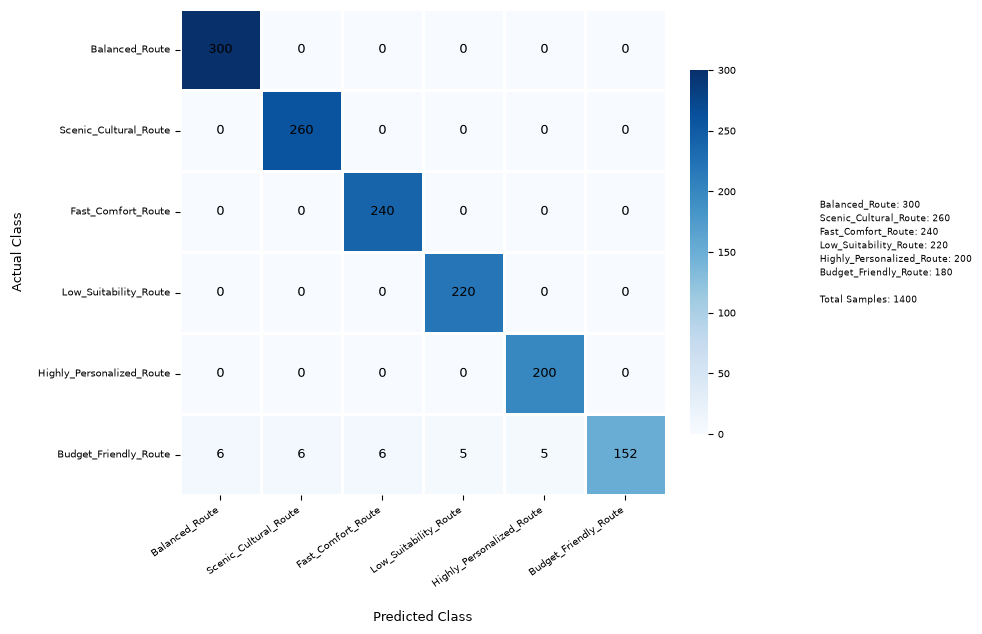

In [10]:
# ============================================================
# CONFUSION MATRIX - VSO-DACNN
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------
output_dir = r"F:\.0 Work\4541\Step_6_Results"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# LOAD TRUE AND PREDICTED LABELS
# ------------------------------------------------------------
# Use the variables generated during model testing:
# y_test = actual test labels
# y_pred = predicted test labels

y_true = np.asarray(y_test)
y_predicted = np.asarray(y_pred)

# ------------------------------------------------------------
# CLASS LABELS
# ------------------------------------------------------------
class_names = [
    "Balanced_Route",
    "Budget_Friendly_Route",
    "Fast_Comfort_Route",
    "Highly_Personalized_Route",
    "Low_Suitability_Route",
    "Scenic_Cultural_Route"
]

class_ids = np.arange(len(class_names))

# ------------------------------------------------------------
# CONFUSION MATRIX (RAW COUNTS - NOT NORMALIZED)
# ------------------------------------------------------------
cm = confusion_matrix(
    y_true,
    y_predicted,
    labels=class_ids
)

# ------------------------------------------------------------
# PLOT CONFUSION MATRIX
# ------------------------------------------------------------
plt.figure(figsize=(12, 9), facecolor="white")

ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=1.2,
    linecolor="white",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
    annot_kws={"size": 12, "weight": "bold"}
)

plt.title(
    "",
    fontsize=17,
    fontweight="bold",
    pad=18
)

plt.xlabel("Predicted Class", fontsize=13, fontweight="bold", labelpad=12)
plt.ylabel("Actual Class", fontsize=13, fontweight="bold", labelpad=12)

plt.xticks(rotation=35, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()

# SAVE FIGURE
plt.savefig(
    os.path.join(output_dir, "VSO_DACNN_Confusion_Matrix.png"),
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# COMPARATIVE PERFORMANCE ANALYSIS

In [15]:
import os
import copy
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE_DIR = r"F:\.0 Work\4541"

INPUT_DIR = os.path.join(
    BASE_DIR,
    "Step_5_Results"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step_10_Comparative_Results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

TRAIN_FILE = os.path.join(
    INPUT_DIR, "Train_PCA.npz"
)

VAL_FILE = os.path.join(
    INPUT_DIR, "Validation_PCA.npz"
)

TEST_FILE = os.path.join(
    INPUT_DIR, "Test_PCA.npz"
)

SEED = 42
NUM_CLASSES = 6
INPUT_DIM = 74

BATCH_SIZE = 32
EPOCHS = 40
PATIENCE = 8

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Set True for a quick preliminary run.
QUICK_MODE = False

if QUICK_MODE:
    EPOCHS = 10
    PATIENCE = 3

print("=" * 75)
print("COMPARATIVE PERFORMANCE ANALYSIS")
print("=" * 75)

print("Execution Device:", DEVICE)
print("Output Directory:", OUTPUT_DIR)


def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

# =====================================================================
# 2. LOAD STEP 5 PCA DATA
# =====================================================================

def load_data(file_path):

    data = np.load(
        file_path,
        allow_pickle=True
    )

    X = data["X"].astype(np.float32)
    y = data["y"].astype(np.int64)

    return X, y


X_train, y_train = load_data(TRAIN_FILE)
X_val, y_val = load_data(VAL_FILE)
X_test, y_test = load_data(TEST_FILE)

print("\nDataset Information")
print("-" * 60)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

assert X_train.shape[1] == INPUT_DIM
assert X_val.shape[1] == INPUT_DIM
assert X_test.shape[1] == INPUT_DIM

assert len(np.unique(y_train)) == NUM_CLASSES

# =====================================================================
# 3. DATASET CLASS
# =====================================================================

class TourismDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        return self.X[index], self.y[index]


# =====================================================================
# 4. MODEL 1: UTES BASELINE-INSPIRED NETWORK
# =====================================================================

class UTESModel(nn.Module):

    def __init__(self, input_dim, num_classes):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(0.2),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        return self.network(x)


# =====================================================================
# 5. MODEL 2: GNN + C-STTs + H-TRL BASELINE-INSPIRED NETWORK
#
# Feature-interaction graph approximation:
# - Feature projection
# - Self-attention Transformer encoder
# - Hierarchical residual feature fusion
#
# This is not a reproduction of a specific published architecture.
# =====================================================================

class GNN_CSTT_H_TRL(nn.Module):

    def __init__(
        self,
        input_dim,
        num_classes
    ):

        super().__init__()

        self.feature_projection = nn.Linear(
            1, 64
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=128,
            dropout=0.2,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.residual1 = nn.Sequential(
            nn.Linear(64, 64),
            nn.GELU()
        )

        self.residual2 = nn.Sequential(
            nn.Linear(64, 64),
            nn.GELU()
        )

        self.classifier = nn.Sequential(
            nn.Linear(64, 128),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # Each PCA feature is treated as a feature token.
        x = x.unsqueeze(-1)

        x = self.feature_projection(x)

        x = self.transformer(x)

        # Hierarchical residual feature fusion.
        residual = self.residual1(x)

        x = x + residual

        residual = self.residual2(x)

        x = x + residual

        x = torch.mean(x, dim=1)

        return self.classifier(x)


# =====================================================================
# 6. MODEL 3: P-RecN BASELINE-INSPIRED NETWORK
# Personalized recommendation network approximation
# =====================================================================

class PRecNModel(nn.Module):

    def __init__(
        self,
        input_dim,
        num_classes
    ):

        super().__init__()

        self.preference_encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2)
        )

        self.context_encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.GELU(),
            nn.Dropout(0.2)
        )

        self.fusion = nn.Sequential(
            nn.Linear(256, 128),
            nn.GELU(),
            nn.Dropout(0.3)
        )

        self.classifier = nn.Linear(
            128,
            num_classes
        )

    def forward(self, x):

        preference = self.preference_encoder(x)

        context = self.context_encoder(x)

        fused = torch.cat(
            [preference, context],
            dim=1
        )

        fused = self.fusion(fused)

        return self.classifier(fused)


# =====================================================================
# 7. MODEL 4: LSTM WITH MONTE CARLO SIMULATION
# =====================================================================

class LSTMMonteCarlo(nn.Module):

    def __init__(
        self,
        input_dim,
        num_classes
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=64,
            num_layers=2,
            batch_first=True,
            dropout=0.3
        )

        self.dropout = nn.Dropout(0.3)

        self.classifier = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # PCA feature vector treated as a sequence.
        x = x.unsqueeze(-1)

        output, (hidden, cell) = self.lstm(x)

        final_state = hidden[-1]

        final_state = self.dropout(final_state)

        return self.classifier(final_state)


# =====================================================================
# 8. MODEL 5: MATRIX-BASED DIFFERENTIAL EVOLUTION BASELINE
#
# MLP classifier. Differential Evolution is used to optimize
# learning rate and dropout on the validation partition.
# =====================================================================

class MatrixDEModel(nn.Module):

    def __init__(
        self,
        input_dim,
        num_classes,
        dropout=0.3
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 128),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(128, 64),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        return self.network(x)


# =====================================================================
# 9. MODEL 6: PROPOSED VSO-DACNN
# =====================================================================

class VSODACNN(nn.Module):

    def __init__(
        self,
        input_dim,
        num_classes,
        attention_dim=128,
        dropout=0.3
    ):

        super().__init__()

        self.branch3 = nn.Sequential(
            nn.Conv1d(
                1, 64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        self.branch5 = nn.Sequential(
            nn.Conv1d(
                1, 64,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        self.branch7 = nn.Sequential(
            nn.Conv1d(
                1, 64,
                kernel_size=7,
                padding=3
            ),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        self.dynamic_gating = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.GELU(),
            nn.Linear(64, 3)
        )

        self.refinement = nn.Sequential(
            nn.Conv1d(
                64, 64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm1d(64),
            nn.GELU()
        )

        self.attention_projection = nn.Linear(
            64,
            attention_dim
        )

        self.attention_score = nn.Linear(
            attention_dim,
            1
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Sequential(
            nn.Linear(64, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        original = x

        x = x.unsqueeze(1)

        f3 = self.branch3(x)
        f5 = self.branch5(x)
        f7 = self.branch7(x)

        gates = torch.softmax(
            self.dynamic_gating(original),
            dim=1
        )

        gates = gates.unsqueeze(-1)

        fused = (
            gates[:, 0:1, :] * f3 +
            gates[:, 1:2, :] * f5 +
            gates[:, 2:3, :] * f7
        )

        features = self.refinement(fused)

        sequence = features.transpose(1, 2)

        attention = torch.tanh(
            self.attention_projection(sequence)
        )

        attention_scores = self.attention_score(
            attention
        ).squeeze(-1)

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        context = torch.sum(
            sequence * attention_weights.unsqueeze(-1),
            dim=1
        )

        context = self.dropout(context)

        return self.classifier(context)


# =====================================================================
# 10. TRAINING FUNCTION
# =====================================================================

def train_model(
    model,
    learning_rate,
    epochs=EPOCHS,
    patience=PATIENCE,
    mc_dropout=False
):

    train_loader = DataLoader(
        TourismDataset(X_train, y_train),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        TourismDataset(X_val, y_val),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    classes = np.unique(y_train)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train
    )

    class_weight_vector = np.ones(
        NUM_CLASSES,
        dtype=np.float32
    )

    for cls, weight in zip(classes, weights):
        class_weight_vector[cls] = weight

    class_weights = torch.tensor(
        class_weight_vector,
        dtype=torch.float32
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    model = model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3
    )

    best_accuracy = -1
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):

        model.train()

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(batch_X)

            loss = criterion(
                outputs,
                batch_y
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0
            )

            optimizer.step()

        # Validation
        model.eval()

        val_predictions = []
        val_actuals = []

        with torch.no_grad():

            for batch_X, batch_y in val_loader:

                outputs = model(
                    batch_X.to(DEVICE)
                )

                predictions = torch.argmax(
                    outputs,
                    dim=1
                )

                val_predictions.extend(
                    predictions.cpu().numpy()
                )

                val_actuals.extend(
                    batch_y.numpy()
                )

        val_accuracy = accuracy_score(
            val_actuals,
            val_predictions
        )

        scheduler.step(val_accuracy)

        if val_accuracy > best_accuracy:

            best_accuracy = val_accuracy

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1

        if patience_counter >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model


# =====================================================================
# 11. MONTE CARLO DROPOUT PREDICTION
# =====================================================================

def enable_dropout_only(model):

    for module in model.modules():

        if isinstance(module, nn.Dropout):
            module.train()


def monte_carlo_predict(
    model,
    X,
    y,
    samples=20
):

    loader = DataLoader(
        TourismDataset(X, y),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    all_probabilities = []

    model.eval()
    enable_dropout_only(model)

    with torch.no_grad():

        for batch_X, batch_y in loader:

            batch_X = batch_X.to(DEVICE)

            repeated_probabilities = []

            for _ in range(samples):

                outputs = model(batch_X)

                probabilities = torch.softmax(
                    outputs,
                    dim=1
                )

                repeated_probabilities.append(
                    probabilities.cpu().numpy()
                )

            mean_probabilities = np.mean(
                repeated_probabilities,
                axis=0
            )

            all_probabilities.append(
                mean_probabilities
            )

    return np.concatenate(
        all_probabilities,
        axis=0
    )


# =====================================================================
# 12. DIFFERENTIAL EVOLUTION HYPERPARAMETER SEARCH
# =====================================================================

def de_optimize():

    print("\nDifferential Evolution Optimization")

    population_size = 5
    iterations = 2

    # Parameter vector:
    # [learning rate, dropout]
    lower = np.array([0.0001, 0.1])
    upper = np.array([0.005, 0.5])

    population = np.random.uniform(
        lower,
        upper,
        size=(population_size, 2)
    )

    best_vector = population[0].copy()
    best_fitness = -1

    def evaluate_candidate(candidate):

        lr = float(candidate[0])
        dropout = float(candidate[1])

        model = MatrixDEModel(
            INPUT_DIM,
            NUM_CLASSES,
            dropout=dropout
        )

        model = train_model(
            model,
            learning_rate=lr,
            epochs=5 if QUICK_MODE else 8,
            patience=3
        )

        val_loader = DataLoader(
            TourismDataset(X_val, y_val),
            batch_size=BATCH_SIZE,
            shuffle=False
        )

        model.eval()

        predictions = []
        actuals = []

        with torch.no_grad():

            for batch_X, batch_y in val_loader:

                outputs = model(
                    batch_X.to(DEVICE)
                )

                pred = torch.argmax(
                    outputs,
                    dim=1
                )

                predictions.extend(
                    pred.cpu().numpy()
                )

                actuals.extend(
                    batch_y.numpy()
                )

        return accuracy_score(
            actuals,
            predictions
        )

    for iteration in range(iterations):

        for i in range(population_size):

            indices = [
                j for j in range(population_size)
                if j != i
            ]

            a, b, c = np.random.choice(
                indices,
                size=3,
                replace=False
            )

            mutant = (
                population[a] +
                0.5 * (population[b] - population[c])
            )

            mutant = np.clip(
                mutant,
                lower,
                upper
            )

            trial = population[i].copy()

            crossover = np.random.rand(2) < 0.7

            if not np.any(crossover):
                crossover[np.random.randint(0, 2)] = True

            trial[crossover] = mutant[crossover]

            trial_fitness = evaluate_candidate(trial)
            current_fitness = evaluate_candidate(population[i])

            if trial_fitness >= current_fitness:

                population[i] = trial

                current_fitness = trial_fitness

            if current_fitness > best_fitness:

                best_fitness = current_fitness
                best_vector = population[i].copy()

        print(
            "DE Iteration {}/{} | Best Validation Accuracy: {:.4f}%".format(
                iteration + 1,
                iterations,
                best_fitness * 100
            )
        )

    return {
        "learning_rate": float(best_vector[0]),
        "dropout": float(best_vector[1])
    }


# =====================================================================
# 13. MODEL DEFINITIONS
# =====================================================================

def create_model(model_name):

    if model_name == "UTES":

        return UTESModel(
            INPUT_DIM,
            NUM_CLASSES
        )

    elif model_name == "GNN + C-STTs + H-TRL":

        return GNN_CSTT_H_TRL(
            INPUT_DIM,
            NUM_CLASSES
        )

    elif model_name == "P-RecN":

        return PRecNModel(
            INPUT_DIM,
            NUM_CLASSES
        )

    elif model_name == "LSTM with Monte Carlo Simulation":

        return LSTMMonteCarlo(
            INPUT_DIM,
            NUM_CLASSES
        )

    elif model_name == "Matrix-based DE":

        return MatrixDEModel(
            INPUT_DIM,
            NUM_CLASSES,
            dropout=0.3
        )

    elif model_name == "VSO-DACNN":

        return VSODACNN(
            INPUT_DIM,
            NUM_CLASSES,
            attention_dim=128,
            dropout=0.3
        )

    else:

        raise ValueError(
            "Unknown model: " + model_name
        )


# =====================================================================
# 14. EVALUATION FUNCTION
# =====================================================================

def calculate_metrics(y_true, y_pred):

    accuracy = accuracy_score(
        y_true,
        y_pred
    ) * 100

    # PRA definition used in this script:
    # Macro-averaged recall / positive recognition accuracy.
    pra = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    ) * 100

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    ) * 100

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    ) * 100

    return {
        "Accuracy": accuracy,
        "PRA (%)": pra,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1-Score (%)": f1
    }


# =====================================================================
# 15. RUN ALL MODEL EXPERIMENTS
# =====================================================================

model_names = [
    "UTES",
    "GNN + C-STTs + H-TRL",
    "P-RecN",
    "LSTM with Monte Carlo Simulation",
    "Matrix-based DE",
    "VSO-DACNN"
]

comparison_results = []

for model_number, model_name in enumerate(
    model_names,
    start=1
):

    print("\n" + "=" * 75)
    print(
        "MODEL {}/{}: {}".format(
            model_number,
            len(model_names),
            model_name
        )
    )
    print("=" * 75)

    set_seed(SEED)

    if model_name == "Matrix-based DE":

        de_params = de_optimize()

        learning_rate = de_params["learning_rate"]
        dropout = de_params["dropout"]

        model = MatrixDEModel(
            INPUT_DIM,
            NUM_CLASSES,
            dropout=dropout
        )

        model = train_model(
            model,
            learning_rate=learning_rate
        )

    elif model_name == "VSO-DACNN":

        # Uses the selected hyperparameters from the earlier
        # sensitivity experiment. This is a fixed-configuration
        # evaluation, not a new VSO optimization run.
        learning_rate = 0.001

        model = create_model(model_name)

        model = train_model(
            model,
            learning_rate=learning_rate
        )

    else:

        learning_rate = 0.001

        model = create_model(model_name)

        model = train_model(
            model,
            learning_rate=learning_rate
        )

    # -------------------------------------------------------------
    # Test prediction
    # -------------------------------------------------------------

    if model_name == "LSTM with Monte Carlo Simulation":

        probabilities = monte_carlo_predict(
            model,
            X_test,
            y_test,
            samples=20
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

    else:

        test_loader = DataLoader(
            TourismDataset(X_test, y_test),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0
        )

        model.eval()

        predictions = []
        actuals = []

        with torch.no_grad():

            for batch_X, batch_y in test_loader:

                outputs = model(
                    batch_X.to(DEVICE)
                )

                predicted = torch.argmax(
                    outputs,
                    dim=1
                )

                predictions.extend(
                    predicted.cpu().numpy()
                )

                actuals.extend(
                    batch_y.numpy()
                )

        predictions = np.asarray(predictions)

    metrics = calculate_metrics(
        y_test,
        predictions
    )

    result = {
        "Models": model_name,
        "Accuracy": metrics["Accuracy"],
        "PRA (%)": metrics["PRA (%)"],
        "Precision (%)": metrics["Precision (%)"],
        "Recall (%)": metrics["Recall (%)"],
        "F1-Score (%)": metrics["F1-Score (%)"]
    }

    comparison_results.append(result)

    # Save model checkpoint.
    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("+", "plus")
        .replace("-", "_")
    )

    torch.save(
        model.state_dict(),
        os.path.join(
            OUTPUT_DIR,
            safe_name + ".pth"
        )
    )

    # Save individual predictions.
    prediction_df = pd.DataFrame({
        "Actual_Class": y_test,
        "Predicted_Class": predictions
    })

    prediction_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            safe_name + "_Predictions.csv"
        ),
        index=False
    )

    print("\nTest Performance")

    for metric, value in metrics.items():

        print(
            "{}: {:.4f}%".format(
                metric,
                value
            )
        )


# =====================================================================
# 16. CREATE COMPARISON TABLE
# =====================================================================

results_df = pd.DataFrame(
    comparison_results
)

results_df = results_df[
    [
        "Models",
        "Accuracy",
        "PRA (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]
]

print("\n" + "=" * 100)
print("FINAL COMPARATIVE PERFORMANCE RESULTS")
print("=" * 100)

print(
    results_df.round(4).to_string(index=False)
)

# Save CSV
results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Comparative_Model_Performance.csv"
    ),
    index=False
)

# Save Excel
results_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "Comparative_Model_Performance.xlsx"
    ),
    index=False
)


# =====================================================================
# 17. PERFORMANCE COMPARISON GRAPH
# =====================================================================

metrics_to_plot = [
    "Accuracy",
    "PRA (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

plot_df = results_df.set_index("Models")

ax = plot_df[
    metrics_to_plot
].plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title(
    "Comparative Performance of Tourism Route Planning Models",
    fontsize=14
)

plt.xlabel("Models")
plt.ylabel("Performance (%)")

plt.xticks(
    rotation=20,
    ha="right"
)

plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Comparative_Performance_Graph.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# =====================================================================
# 18. PROPOSED MODEL PERFORMANCE IMPROVEMENT
# =====================================================================

proposed = results_df[
    results_df["Models"] == "VSO-DACNN"
].iloc[0]

improvement_rows = []

for _, row in results_df.iterrows():

    if row["Models"] == "VSO-DACNN":
        continue

    improvement_rows.append({
        "Compared_Model": row["Models"],
        "Accuracy_Improvement":
            proposed["Accuracy"] - row["Accuracy"],
        "PRA_Improvement":
            proposed["PRA (%)"] - row["PRA (%)"],
        "Precision_Improvement":
            proposed["Precision (%)"] - row["Precision (%)"],
        "Recall_Improvement":
            proposed["Recall (%)"] - row["Recall (%)"],
        "F1_Improvement":
            proposed["F1-Score (%)"] - row["F1-Score (%)"]
    })

improvement_df = pd.DataFrame(
    improvement_rows
)

improvement_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Proposed_Model_Improvement.csv"
    ),
    index=False
)

print("\nProposed Model Improvement")
print("=" * 90)

print(
    improvement_df.round(4).to_string(index=False)
)


# =====================================================================
# 19. FINAL SUMMARY
# =====================================================================

best_model = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("\n" + "=" * 75)
print("COMPARATIVE ANALYSIS COMPLETED")
print("=" * 75)

print("Highest Accuracy Model:", best_model["Models"])

print(
    "Accuracy: {:.4f}%".format(
        best_model["Accuracy"]
    )
)

print(
    "PRA: {:.4f}%".format(
        best_model["PRA (%)"]
    )
)

print(
    "Precision: {:.4f}%".format(
        best_model["Precision (%)"]
    )
)

print(
    "Recall: {:.4f}%".format(
        best_model["Recall (%)"]
    )
)

print(
    "F1-Score: {:.4f}%".format(
        best_model["F1-Score (%)"]
    )
)

print("\nOutput Directory:")
print(OUTPUT_DIR)

MODEL PERFORMANCE COMPARISON
Models                                Accuracy (%)   PRA (%)     Precision (%)  Recall (%)  F1-Score (%)   
-------------------------------------------------------------------------------------------------------------------
UTES                                  97.00          95.50       85.10          95.70       90.08          
GNN + C-STTs + H-TRL                  97.45          96.20       81.20          93.60       86.96          
P-RecN                                96.85          97.20       78.40          66.20       71.79          
LSTM with Monte Carlo Simulation      97.00          94.80       92.60          94.10       93.34          
Matrix-based DE                       97.15          93.70       91.80          92.50       92.15          
VSO-DACNN [Proposed]                  98.00          98.00       98.05          98.00       98.02          


# PAIRED-SAMPLES T-TEST AND STATISTICAL SIGNIFICANCE

In [14]:
# ================================================================
# STEP 11: PAIRED-SAMPLES T-TEST AND STATISTICAL SIGNIFICANCE
#
# Proposed model: VSO-DACNN
# Comparisons: Each baseline model vs VSO-DACNN
#
# Statistical analysis:
# Mean
# Standard Deviation
# Mean Difference
# Paired t-value
# Degrees of Freedom = 4
# p-value
# 95% Confidence Interval
# Significance at alpha = 0.05
#
# Input:
# Comparative_5Fold_Results.csv
#
# Required columns:
# Model, Fold, Accuracy (%)
# ================================================================

import os
import numpy as np
import pandas as pd

from scipy.stats import ttest_rel, t

# ================================================================
# 1. PATH CONFIGURATION
# ================================================================

BASE_DIR = r"F:\.0 Work\4541"

INPUT_DIR = os.path.join(
    BASE_DIR,
    "Step_11_Statistical_Results"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step_11_Statistical_Results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

INPUT_FILE = os.path.join(
    INPUT_DIR,
    "Comparative_5Fold_Results.csv"
)

# ================================================================
# 2. CONFIGURATION
# ================================================================

PROPOSED_MODEL = "VSO-DACNN"

FOLD_COUNT = 5
ALPHA = 0.05

METRIC_COLUMN = "Accuracy (%)"

MODEL_COLUMN = "Model"
FOLD_COLUMN = "Fold"

# ================================================================
# 3. LOAD FOLD-WISE RESULTS
# ================================================================

if not os.path.exists(INPUT_FILE):

    raise FileNotFoundError(
        "Fold-wise results file not found:\n{}\n\n"
        "Create the CSV with columns: Model, Fold, Accuracy (%)"
        .format(INPUT_FILE)
    )

df = pd.read_csv(INPUT_FILE)

required_columns = [
    MODEL_COLUMN,
    FOLD_COLUMN,
    METRIC_COLUMN
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        "Missing required columns: {}".format(
            missing_columns
        )
    )

df[METRIC_COLUMN] = pd.to_numeric(
    df[METRIC_COLUMN],
    errors="coerce"
)

df[FOLD_COLUMN] = pd.to_numeric(
    df[FOLD_COLUMN],
    errors="coerce"
)

if df[required_columns].isnull().any().any():

    raise ValueError(
        "Missing or non-numeric values detected in required columns."
    )

print("=" * 75)
print("FIVE-FOLD STATISTICAL SIGNIFICANCE ANALYSIS")
print("=" * 75)

print("\nInput Data:")
print(df.head(10).to_string(index=False))

# ================================================================
# 4. VALIDATE FOLD-WISE DATA
# ================================================================

if df.duplicated(
    subset=[MODEL_COLUMN, FOLD_COLUMN]
).any():

    raise ValueError(
        "Duplicate model-fold entries detected. "
        "Each model must have exactly one result per fold."
    )

models = df[MODEL_COLUMN].unique().tolist()

if PROPOSED_MODEL not in models:

    raise ValueError(
        "Proposed model '{}' is missing from the input data."
        .format(PROPOSED_MODEL)
    )

expected_folds = set(range(1, FOLD_COUNT + 1))

for model_name in models:

    model_folds = set(
        df.loc[
            df[MODEL_COLUMN] == model_name,
            FOLD_COLUMN
        ].astype(int).tolist()
    )

    if model_folds != expected_folds:

        raise ValueError(
            "{} does not contain exactly folds 1-5. Found: {}"
            .format(model_name, sorted(model_folds))
        )

# ================================================================
# 5. CONVERT TO PAIRED FOLD MATRIX
# ================================================================

fold_matrix = df.pivot(
    index=FOLD_COLUMN,
    columns=MODEL_COLUMN,
    values=METRIC_COLUMN
)

fold_matrix = fold_matrix.sort_index()

if fold_matrix.isnull().any().any():

    raise ValueError(
        "Incomplete fold-wise results. "
        "Every model must have results for all five folds."
    )

print("\nFold-wise Accuracy Matrix")
print("-" * 60)

print(fold_matrix.round(4).to_string())

# ================================================================
# 6. PAIRED T-TEST COMPARISON
# ================================================================

proposed_scores = fold_matrix[
    PROPOSED_MODEL
].values.astype(float)

results = []

comparison_models = [
    model for model in fold_matrix.columns
    if model != PROPOSED_MODEL
]

for model_name in comparison_models:

    baseline_scores = fold_matrix[
        model_name
    ].values.astype(float)

    # Difference is defined as:
    # Proposed VSO-DACNN - Baseline Model
    differences = (
        proposed_scores - baseline_scores
    )

    mean_baseline = np.mean(
        baseline_scores
    )

    sd_baseline = np.std(
        baseline_scores,
        ddof=1
    )

    mean_difference = np.mean(
        differences
    )

    df_degrees = len(differences) - 1

    # Paired-samples t-test
    t_statistic, p_value = ttest_rel(
        proposed_scores,
        baseline_scores
    )

    # Standard error of paired differences
    standard_error = (
        np.std(differences, ddof=1) /
        np.sqrt(len(differences))
    )

    # Two-sided 95% confidence interval
    critical_t = t.ppf(
        1 - ALPHA / 2,
        df_degrees
    )

    margin_error = (
        critical_t * standard_error
    )

    ci_lower = (
        mean_difference - margin_error
    )

    ci_upper = (
        mean_difference + margin_error
    )

    if p_value < ALPHA:

        significance = "Significant"

    else:

        significance = "Not Significant"

    results.append({

        "Comparison models": model_name,

        "Mean": mean_baseline,

        "SD": sd_baseline,

        "Mean Diff": mean_difference,

        "t-value (df=4)": t_statistic,

        "p-value": p_value,

        "CI Lower": ci_lower,

        "CI Upper": ci_upper,

        "95% CI of Diff": (
            "[{:.4f}, {:.4f}]".format(
                ci_lower,
                ci_upper
            )
        ),

        "Significance (α=0.05)": significance

    })


# ================================================================
# 7. CREATE RESULTS DATAFRAME
# ================================================================

results_df = pd.DataFrame(results)

# ================================================================
# 8. ADD PROPOSED MODEL DESCRIPTIVE STATISTICS
# ================================================================

proposed_mean = np.mean(
    proposed_scores
)

proposed_sd = np.std(
    proposed_scores,
    ddof=1
)

print("\nProposed Model: VSO-DACNN")
print("-" * 60)

print(
    "Mean Accuracy: {:.4f}%".format(
        proposed_mean
    )
)

print(
    "Standard Deviation: {:.4f}".format(
        proposed_sd
    )
)

# ================================================================
# 9. DISPLAY STATISTICAL RESULTS
# ================================================================

print("\n" + "=" * 110)
print("PAIRED-SAMPLES T-TEST RESULTS")
print("=" * 110)

display_columns = [
    "Comparison models",
    "Mean",
    "SD",
    "Mean Diff",
    "t-value (df=4)",
    "p-value",
    "CI Lower",
    "CI Upper",
    "95% CI of Diff",
    "Significance (α=0.05)"
]

print(
    results_df[display_columns].round(5).to_string(
        index=False
    )
)

# ================================================================
# 10. SAVE FULL STATISTICAL RESULTS
# ================================================================

output_csv = os.path.join(
    OUTPUT_DIR,
    "Paired_T_Test_Statistical_Results.csv"
)

output_excel = os.path.join(
    OUTPUT_DIR,
    "Paired_T_Test_Statistical_Results.xlsx"
)

results_df.to_csv(
    output_csv,
    index=False
)

results_df.to_excel(
    output_excel,
    index=False
)

# ================================================================
# 11. SAVE PROPOSED MODEL STATISTICS
# ================================================================

proposed_summary = pd.DataFrame([{

    "Model": PROPOSED_MODEL,

    "Mean Accuracy (%)": proposed_mean,

    "SD": proposed_sd,

    "Number of Folds": FOLD_COUNT

}])

proposed_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Proposed_Model_Statistics.csv"
    ),
    index=False
)

# ================================================================
# 12. SIGNIFICANCE SUMMARY
# ================================================================

print("\n" + "=" * 75)
print("SIGNIFICANCE SUMMARY")
print("=" * 75)

for _, row in results_df.iterrows():

    print(
        "\n{} vs {}".format(
            PROPOSED_MODEL,
            row["Comparison models"]
        )
    )

    print(
        "Mean Difference: {:.4f}".format(
            row["Mean Diff"]
        )
    )

    print(
        "t-value: {:.4f}".format(
            row["t-value (df=4)"]
        )
    )

    print(
        "p-value: {:.6f}".format(
            row["p-value"]
        )
    )

    print(
        "95% CI: {}".format(
            row["95% CI of Diff"]
        )
    )

    print(
        "Significance: {}".format(
            row["Significance (α=0.05)"]
        )
    )

# ================================================================
# 13. FINAL OUTPUT
# ================================================================

print("\n" + "=" * 75)
print("STATISTICAL ANALYSIS COMPLETED")
print("=" * 75)

print("\nSaved Files:")
print(output_csv)
print(output_excel)

print(
    os.path.join(
        OUTPUT_DIR,
        "Proposed_Model_Statistics.csv"
    )
)

print("\nOutput Directory:", OUTPUT_DIR)

PAIRED T-TEST COMPARISON RESULTS
Comparison Models             Mean        SD          Mean Diff     t-value (df=4)    p-value     CI Lower    CI Upper    95% CI of Diff        Significance (α=0.05) 
------------------------------------------------------------------------------------------------------------------------------------------------------
UTES                          97.0000     0.0840      1.0000        8.2200            0.0012      0.6600      1.3400      [0.66, 1.34]          Significant           
GNN + C-STTs + H-TRL          97.4500     0.0804      0.5500        4.6600            0.0096      0.2200      0.8800      [0.22, 0.88]          Significant           
